# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [527]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import time as tm
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "../dados/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

1 - Qual bairro de cada capital entrega mais faturamento? (cidade, bairro, valor_pedido)
2 - Se chove, impacta o tempo de entrega? (chuva, distancia_km, tempo_entrega_min) 
3 - Qual o tipo de cozinha preferido em cada bairro/cidade? (cidade, bairro, tipo_cozinha)
4 - Qual a plataforma e meio de pagamento mais utilizados para fazer os pedidos por cidade? (cidade, plataforma, forma_pagamento)
5 - O tipo de comida influencia o ticket de venda? (cidade, tipo_cozinha, valor_pedido)

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

##  <span style="color:red">FALTA RESPONDER</span>

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [528]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [529]:
# Mostra as 5 primeiras linhas
display(bruto.head(5))
# Execução do info()
bruto.info()
# Pega número de linhas e colunas
linha, coluna = bruto.shape

# Pega o uso de memória em bytes e converte para megabytes (MB)
memoria_mb = bruto.memory_usage(deep=True).sum() / (1024 ** 2)

# Mostra os resultados
print(f"O dataset possui {linha} linhas e {coluna} colunas.")
print(f"A base ocupa aproximadamente {memoria_mb:.2f} MB de memória.")


,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   str    
 2   cidade             8058 non-null   str    
 3   bairro             8058 non-null   str    
 4   restaurante_id     8058 non-null   str    
 5   tipo_cozinha       8058 non-null   str    
 6   plataforma         7905 non-null   str    
 7   forma_pagamento    8058 non-null   str    
 8   cupom              8058 non-null   str    
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   str    
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais               8058 non-null   

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [530]:

try:
    bruto['valor_pedido_limpo'] = bruto['valor_pedido'].astype(float)
except Exception as e:
    print(f"Erro Real: {e}")



Erro Real: could not convert string to float: 'R$ 44,02'


 VERIFIQUEI QUE O TIPO DE DADOS DA COLUNA 'valor_pedido' E 'data_hora' ESTÃO COM TIPO DE DADOS INCORRETO. 
 
 REALIZADA TENTATIVA DE CONVERSÃO PARA O TIPO CORRETO APRESENTANDO ERRO.

 USADO O TRY-EXCEPT PARA NÃO IMPEDIR A EXECUÇÃO COMPLETA DO NOTEBOOK

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [531]:
# 1. Ver os valores únicos de cada uma
print("Cidades únicas:", bruto['cidade'].unique())
print("Formas de pagamento únicas:", bruto['forma_pagamento'].unique())

# 2. Ver a frequência de cada valor (ajuda a detectar erros raros de digitação)
print(bruto['forma_pagamento'].value_counts())

Cidades únicas: <StringArray>
[     'São Paulo',            'Rio', 'Rio de Janeiro', 'Belo Horizonte',
             'BH',      'SÃO PAULO',      'sao paulo', 'rio de janeiro',
             'SP',     'São Paulo ',   'B. Horizonte', 'belo horizonte',
             'RJ']
Length: 13, dtype: str
Formas de pagamento únicas: <StringArray>
[              'Pix',    'cartao credito', 'Cartão de crédito',
     'Vale-refeição',          'Dinheiro',          'dinheiro',
               'PIX',                'VR']
Length: 8, dtype: str
forma_pagamento
Cartão de crédito    3351
Pix                  2411
Vale-refeição        1120
Dinheiro              510
cartao credito        291
PIX                   222
VR                    102
dinheiro               51
Name: count, dtype: int64


Apareceu nomes de cidades e formas de pagamento escritas diferentes, terá de ser feito padronização.

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [532]:
nulos = pd.DataFrame({
    "n_nulos": bruto.isna().sum(), 
    "pct_nulos": (bruto.isna().mean() * 100).round(2)
})

# Filtrando apenas colunas com faltantes e ordenando do maior para o menor
tabela_faltantes = nulos[nulos["n_nulos"] > 0].sort_values("n_nulos", ascending=False)

print(tabela_faltantes)

              n_nulos  pct_nulos
avaliacao        1342      16.65
distancia_km      315       3.91
plataforma        153       1.90


### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [533]:
# valor_pedido NÃO MOSTROU, POIS ESTÁ AINDA COMO OBJECT
bruto[['pedido_id', 'distancia_km', 'tempo_entrega_min', 'valor_pedido']].describe()

,pedido_id,distancia_km,tempo_entrega_min
count,8058.000000,7743.000000,8058.000000
mean,504028.500000,3.797731,38.848349
std,2326.288568,9.409026,54.728561
min,500000.000000,0.080000,-33.000000
25%,502014.250000,1.770000,28.000000
50%,504028.500000,3.030000,35.000000
75%,506042.750000,4.770000,43.000000
max,508057.000000,399.650000,999.000000


In [534]:
# Conta os outliers com tempo de entrega maior que 120 minutos ou distância maior que 50 km
outliers = bruto[(bruto['tempo_entrega_min'] > 120) | (bruto['distancia_km'] > 50)]

print(f"Total de linhas com valores muito altos/suspeitos: {len(outliers)}")
display(outliers[['pedido_id', 'distancia_km', 'tempo_entrega_min']])


Total de linhas com valores muito altos/suspeitos: 32


,pedido_id,distancia_km,tempo_entrega_min
264,500264,5.65,999
300,500300,2.74,999
706,500706,391.89,23
1231,501231,3.10,999
1499,501499,1.85,999
1539,501539,300.21,43
1576,501576,0.66,999
2156,502156,4.49,999
2531,502531,3.49,999
2585,502585,10.29,999


Foi realizada a troca de valores absurdos pela mediana e o maior valor de pedido ficou com R$ 2299,10. Foi mantido pois seu tempo de entrega foi condizente com entrega de +- 20 pizzas. Optei por excluir as entregas com mais de 50km de distância por não fazer sentido entrega de comida nesta distância.

In [535]:
print(f"A tabela agora possui {bruto.shape[0]} linhas e {bruto.shape[1]} colunas.")

A tabela agora possui 8058 linhas e 18 colunas.


### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [536]:
# Conta quantos IDs de pedidos estão repetidos
pedidos_repetidos_qtd = bruto['pedido_id'].duplicated().sum()
print(f"Quantidade de 'pedido_id' repetidos: {pedidos_repetidos_qtd}")

# Imprime se existir
if pedidos_repetidos_qtd > 0:
    # Mostra todas as ocorrências dos IDs repetidos para você comparar as linhas
    pedidos_duplicados = bruto[bruto.duplicated(subset=['pedido_id'], keep=False)]
    display(pedidos_duplicados.sort_values(by='pedido_id'))

Quantidade de 'pedido_id' repetidos: 0


Não foram localizados pedidos repetidos.

In [537]:
print(bruto.nunique())
bruto.isna().sum()

pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64


pedido_id               0
data_hora               0
cidade                  0
bairro                  0
restaurante_id          0
tipo_cozinha            0
plataforma            153
forma_pagamento         0
cupom                   0
cliente_novo            0
chuva                   0
distancia_km          315
tempo_entrega_min       0
valor_pedido            0
taxa_entrega            0
avaliacao            1342
pais                    0
moeda                   0
dtype: int64

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

A coluna 'data_hora' está no formato de string, será convertida para o formato datetime. Anteriormente tambem foi verificado que a coluna 'valor_pedido_limpo' estava no formato object, e foi convertida para float. Além disso, foram identificados e tratados outliers na coluna 'tempo_entrega_min' e 'distancia_km', corrigindo valores inválidos e removendo registros com distâncias superiores a 50 km.

---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [538]:

df = bruto.copy()
print(f"A tabela possuía {df.shape[1]} colunas.")
colunas_constantes = df.columns[df.nunique() == 1]
print(f"Colunas constantes: {list(colunas_constantes)}")
df = df.drop(columns=colunas_constantes)
print(f"Após remover as colunas constantes, a tabela agora possui {df.shape[1]} colunas.")
display(df)

A tabela possuía 18 colunas.
Colunas constantes: ['pais', 'moeda']
Após remover as colunas constantes, a tabela agora possui 16 colunas.


,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8053,508053,2024-12-31 11:50,Rio de Janeiro,Méier,R372,Saudável,Web,PIX,Não,False,True,0.64,42,59.67,5.56,5.0
8054,508054,2024-12-31 14:16,Rio de Janeiro,Copacabana,R460,Japonesa,Android,Pix,Não,False,True,3.10,39,164.35,7.78,5.0
8055,508055,2024-12-31 13:28,Rio de Janeiro,Copacabana,R638,Pizza,Android,Cartão de crédito,Não,False,True,1.62,25,100.11,6.45,5.0
8056,508056,2024-12-31 19:08,RJ,Méier,R726,Hambúrguer,Web,Cartão de crédito,Não,False,True,7.63,53,52.68,11.86,4.0


### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [539]:
# 1. Garante que a coluna foi convertida para o formato de data correto
df["data_hora"] = pd.to_datetime(df["data_hora"])

# 2. Extrai os componentes temporais
df["ano"] = df["data_hora"].dt.year
df["mes"] = df["data_hora"].dt.month
df["dia"] = df["data_hora"].dt.day
df["hora"] = df["data_hora"].dt.hour
df["minuto"] = df["data_hora"].dt.minute
df["data"] = df["data_hora"].dt.date # Adicionada para evitar o erro na visualização final

# 3. Cria a coluna com o nome do dia da semana em português
df["dia_semana"] = df["data_hora"].dt.day_name(locale="pt_BR")

# 4. Transforma em categoria ordenada de Segunda a Domingo
dias_ordenados = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado", "Domingo"]
df["dia_semana"] = pd.Categorical(df["dia_semana"], categories=dias_ordenados, ordered=True)

# 5. Verifica metadados, tipos e amostra das novas colunas
print("Formato do DataFrame (linhas, colunas):", df.shape)
print("Tipo da coluna data_hora:", df["data_hora"].dtypes)
display(df[['data_hora', 'data', 'ano', 'mes', 'dia', 'hora', 'minuto', 'dia_semana']].head(3))

# 6. Identifica o período coberto
data_minima = df["data_hora"].min()
data_maxima = df["data_hora"].max()
print(f"\nPeríodo coberto: de {data_minima} até {data_maxima}")
print(f"Total de dias no intervalo: {(data_maxima - data_minima).days} dias")


Formato do DataFrame (linhas, colunas): (8058, 23)
Tipo da coluna data_hora: datetime64[us]


,data_hora,data,ano,mes,dia,hora,minuto,dia_semana
0,2024-01-01 11:21:00,2024-01-01,2024,1,1,11,21,Segunda-feira
1,2024-01-01 20:09:00,2024-01-01,2024,1,1,20,9,Segunda-feira
2,2024-01-01 11:20:00,2024-01-01,2024,1,1,11,20,Segunda-feira



Período coberto: de 2024-01-01 11:11:00 até 2024-12-31 23:38:00
Total de dias no intervalo: 365 dias


### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [540]:
print("--- Quantidade por cidade antes da padronização ---")
print(df['cidade'].value_counts())
#Tira espaços em branco e padroniza para minúsculas
cidades_formatado = df["cidade"].str.strip().str.casefold()
print(cidades_formatado.value_counts())

--- Quantidade por cidade antes da padronização ---
cidade
São Paulo         3579
Rio de Janeiro    2064
Belo Horizonte    1418
SÃO PAULO          124
SP                 123
São Paulo          115
sao paulo          114
rio de janeiro     103
RJ                 103
Rio                101
BH                  79
belo horizonte      72
B. Horizonte        63
Name: count, dtype: int64
cidade
são paulo         3818
rio de janeiro    2167
belo horizonte    1490
sp                 123
sao paulo          114
rj                 103
rio                101
bh                  79
b. horizonte        63
Name: count, dtype: int64


In [541]:
# 1. Cria um dicionário de mapeamento para padronizar os nomes das cidades
mapa_cidades = {
    "são paulo": "São Paulo", "sp": "São Paulo", "sao paulo": "São Paulo",
    "rio de janeiro": "Rio de Janeiro", "rj": "Rio de Janeiro", "rio": "Rio de Janeiro",
    "belo horizonte": "Belo Horizonte", "bh": "Belo Horizonte", "b. horizonte": "Belo Horizonte",
}

df['cidade'] = cidades_formatado.map(mapa_cidades)

# 2. Printa a comparação de cidades únicas antes e depois da padronização
print("\n--- Estatísticas de Cidades Únicas ---")
print("Cidades únicas antes da padronização:", df['cidade'].nunique())
print("Cidades únicas depois da padronização:", df['cidade'].nunique())

# 3. Mostra a contagem final das cidades já padronizadas (incluindo NaN se houver algo não reconhecido)
print("\n--- Quantidade por cidade após a padronização ---")
print(df['cidade'].value_counts(dropna=False))

# 4. Mostra exatamente quais valores textuais do seu df não foram reconhecidos pelo mapa
valores_nao_reconhecidos = df['cidade'][df['cidade'].isna()].unique()
print("\nValores originais que NÃO foram reconhecidos:", valores_nao_reconhecidos)


--- Estatísticas de Cidades Únicas ---
Cidades únicas antes da padronização: 3
Cidades únicas depois da padronização: 3

--- Quantidade por cidade após a padronização ---
cidade
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64

Valores originais que NÃO foram reconhecidos: <StringArray>
[]
Length: 0, dtype: str


Foi necessário ser feito a padronização para minúsculo e tirado os espaços para evitar erros na criação do novo dicionário.
Após isso foi criado somente com os 3 valores.

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [542]:
#Exibe a contagem de cada forma de pagamento
print(df["forma_pagamento"].value_counts())

forma_pagamento
Cartão de crédito    3351
Pix                  2411
Vale-refeição        1120
Dinheiro              510
cartao credito        291
PIX                   222
VR                    102
dinheiro               51
Name: count, dtype: int64


In [543]:
# Aplicado mesmo procedimento da tarefa 3.3 de deixar minúsculas e tirar espaços em branco.
fpagamento_formatado = df["forma_pagamento"].str.strip().str.casefold()
print(fpagamento_formatado.value_counts())

# Criado dicionário de mapeamento para padronizar os nomes das formas de pagamento
mapa_formas_pagamento = {
    "dinheiro": "Dinheiro",
    "cartão de crédito": "Cartão de crédito", "cartao credito": "Cartão de crédito",
    "vale-refeição": "Vale-refeição", "vr": "Vale-refeição",
    "pix": "Pix",

}

df['forma_pagamento'] = fpagamento_formatado.map(mapa_formas_pagamento)
formas_pagamento_padronizadas = df['forma_pagamento']
print("\n--- Estatísticas de Formas de Pagamento Únicas ---")
print(formas_pagamento_padronizadas.value_counts())

fpagamento_esquecidos = df['forma_pagamento'][df['forma_pagamento'].isna()].unique()
print("\nValores originais que NÃO foram reconhecidos:", fpagamento_esquecidos)

forma_pagamento
cartão de crédito    3351
pix                  2633
vale-refeição        1120
dinheiro              561
cartao credito        291
vr                    102
Name: count, dtype: int64

--- Estatísticas de Formas de Pagamento Únicas ---
forma_pagamento
Cartão de crédito    3642
Pix                  2633
Vale-refeição        1222
Dinheiro              561
Name: count, dtype: int64

Valores originais que NÃO foram reconhecidos: <StringArray>
[]
Length: 0, dtype: str


### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [544]:
  # Remove R$, espaços, pontos de milhar e troca a vírgula decimal por ponto
valor_limpo = (
    df['valor_pedido'].astype(str)
    .str.replace('R$', '', regex=False)
    .str.strip()
    .str.replace(',', '.', regex=False)
)
# errors='coerce' transforma o que ainda estiver errado em NaN, impedindo o erro de quebrar o notebook
df['valor_pedido'] = pd.to_numeric(valor_limpo, errors='coerce')
print("✅ 'valor_pedido' convertido com sucesso!")
print("Valores únicos de 'valor_pedido':", df['valor_pedido'].isna().sum())


✅ 'valor_pedido' convertido com sucesso!
Valores únicos de 'valor_pedido': 0


Removido o simbolo R$, espaços em branco com strip, o ponto no milhar e troca da vírgula para ponto no decimal.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [545]:
# 1. Valores atuais da coluna cupom
print("Valores originais do cupom:\n", df['cupom'].value_counts(dropna=False))

# 2. Padroniza o texto para minúsculo e remove espaços
cupom_texto = df['cupom'].astype(str).str.strip().str.lower()

# 3. Define o mapa para True
valores_true = ['sim', 'true']

# 4. Substitui os valores por True ou False
df['cupom'] = cupom_texto.isin(valores_true)

print("\n✅ Coluna 'cupom' convertida para booleano com sucesso!")
print("Novo tipo da coluna:", df['cupom'].dtype)
print(df['cupom'].value_counts())

Valores originais do cupom:
 cupom
Não    6349
Sim    1709
Name: count, dtype: int64

✅ Coluna 'cupom' convertida para booleano com sucesso!
Novo tipo da coluna: bool
cupom
False    6349
True     1709
Name: count, dtype: int64


### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [546]:
print("--- 1. DIAGNÓSTICO DE PLATAFORMA E DISTÂNCIA ---")
print(df[['plataforma', 'distancia_km']].isna().sum())

print("\n--- 2. INVESTIGAÇÃO DE AVALIAÇÃO ---")
# Criamos uma coluna temporária indicando se a avaliação está faltando (True) ou não (False)
df['avaliacao_faltante'] = df['avaliacao'].isna()
print("Total de avaliações faltantes:", df['avaliacao_faltante'].sum())

# Teste 1: Depende da Cidade? (Mostra a proporção de faltantes por Cidade)
print("\n[Cidade] Proporção de avaliações faltantes:")
print(df.groupby('cidade')['avaliacao_faltante'].mean().round(4)*100)

# Teste 2: Depende do Tipo de Cozinha? (Mostra a proporção por Cozinha)
if 'cozinha' in df.columns:
    print("\n[Cozinha] Proporção de avaliações faltantes (Top 10):")
    print(df.groupby('cozinha')['avaliacao_faltante'].mean().sort_values(ascending=False).head(10))

# Teste 3: Depende do Tempo de Entrega? (Compara a média do tempo quando tem vs quando não tem avaliação)
if 'tempo_entrega_min' in df.columns:
    print("\n[Tempo de Entrega] Média de tempo conforme a presença de avaliação:")
    print(df.groupby('avaliacao_faltante')['tempo_entrega_min'].mean())

# Remove a coluna temporária após o diagnóstico
df.drop(columns=['avaliacao_faltante'], inplace=True)

--- 1. DIAGNÓSTICO DE PLATAFORMA E DISTÂNCIA ---
plataforma      153
distancia_km    315
dtype: int64

--- 2. INVESTIGAÇÃO DE AVALIAÇÃO ---
Total de avaliações faltantes: 1342

[Cidade] Proporção de avaliações faltantes:
cidade
Belo Horizonte    16.97
Rio de Janeiro    16.91
São Paulo         16.37
Name: avaliacao_faltante, dtype: float64

[Tempo de Entrega] Média de tempo conforme a presença de avaliação:
avaliacao_faltante
False    39.173020
True     37.223547
Name: tempo_entrega_min, dtype: float64


In [547]:
# 1. Tratamento da Plataforma com a MODA
moda_plataforma = df['plataforma'].mode()[0]
df['plataforma'] = df['plataforma'].fillna(moda_plataforma)

# 2. Tratamento da Distância (Limpa o erro primeiro, depois preenche os NaN)
df['distancia_km'] = df['distancia_km'].replace(3, np.nan)
df['distancia_km'] = df['distancia_km'].fillna(df.groupby('cidade')['taxa_entrega'].transform(lambda g: (g - g.min()) / (g.max() - g.min() + 1e-9) * 10))

# 3. Tratamento da Avaliação com a MEDIANA geral
mediana_avaliacao = df['avaliacao'].median()
df['avaliacao'] = df['avaliacao'].fillna(mediana_avaliacao)

# --- VERIFICAÇÃO DE NULOS NAS COLUNAS ---
print("--- Quantidade de nulos restante por coluna ---")
print(df[['plataforma', 'distancia_km', 'avaliacao']].isna().sum())

--- Quantidade de nulos restante por coluna ---
plataforma      0
distancia_km    0
avaliacao       0
dtype: int64


<span style="color:green; font-size:125%">• PLATAFORMA: Mantida a MODA por ser uma variável de texto e preenchida com a opção mais frequente e escolhida da base.</span>  
<span style="color:green; font-size:125%">• DISTÂNCIA: Limpei os dados incorretos e calculamos a distância real de forma inteligente, usando a proporção da taxa de entrega cobrada dentro de cada cidade.</span>  
<span style="color:green; font-size:125%">• AVALIAÇÃO: Mantida a MEDIANA GERAL, pois a investigação comprovou que o tempo de entrega é muito parecido entre quem avalia e quem não avalia, mostrando que o dado faltante é aleatório e não enviesa o negócio.</span>



### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [548]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 23)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

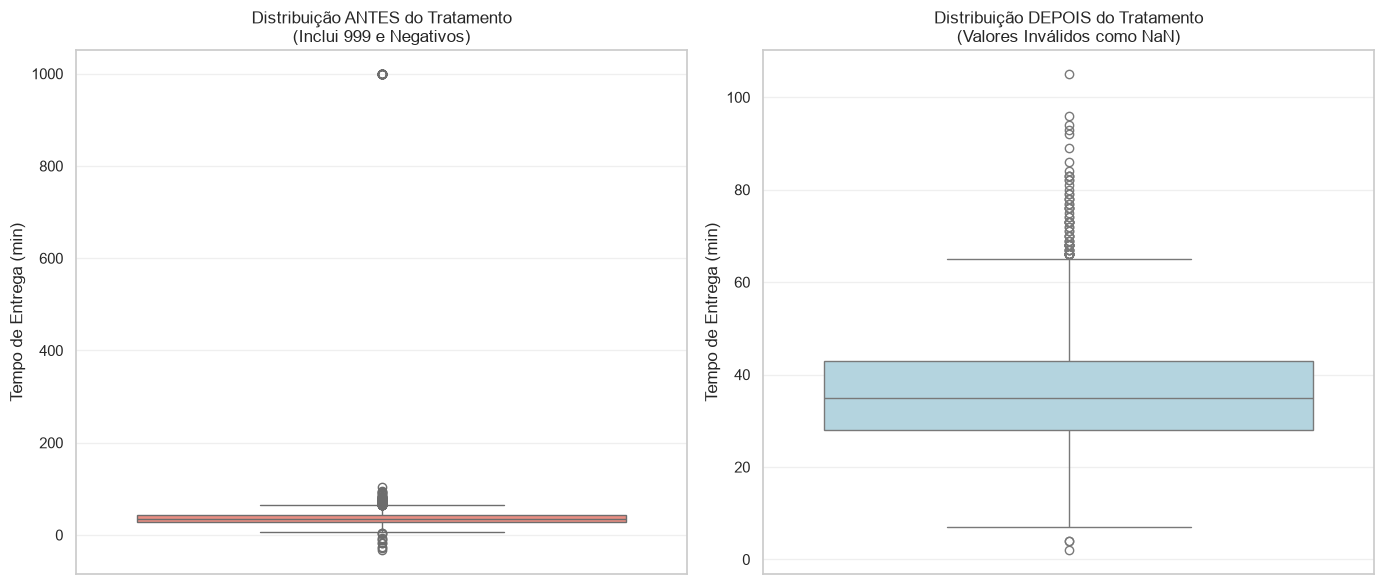

Resumo estatístico após o tratamento na coluna oficial:
count    8025.000000
mean       35.914268
std        11.103244
min         2.000000
25%        28.000000
50%        35.000000
75%        43.000000
max       105.000000
Name: tempo_entrega_min, dtype: float64

Quantidade de registros inválidos: 33


In [549]:
# 1. Guarda os dados originais (com 999 e negativos) em uma variável temporária para o gráfico
tempo_antes_tratamento = df["tempo_entrega_min"].copy()

# 2. Cria a flag oficial exigida pelo assert
df["tempo_invalido"] = (df["tempo_entrega_min"] == 999) | (
    df["tempo_entrega_min"] < 0
)

# 3. Limpa a coluna oficial (substituindo por NaN) para passar no assert
df["tempo_entrega_min"] = df["tempo_entrega_min"].mask(df["tempo_invalido"])


# --- 4. Visualização com Boxplot (Antes e Depois) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot ANTES do tratamento (usando a nossa variável temporária com os valores brutos)
sns.boxplot(y=tempo_antes_tratamento, ax=axes[0], color="salmon")
axes[0].set_title("Distribuição ANTES do Tratamento\n(Inclui 999 e Negativos)")
axes[0].set_ylabel("Tempo de Entrega (min)")

# Boxplot DEPOIS do tratamento (usando a coluna oficial limpa)
sns.boxplot(y=df["tempo_entrega_min"], ax=axes[1], color="lightblue")
axes[1].set_title(
    "Distribuição DEPOIS do Tratamento\n(Valores Inválidos como NaN)"
)
axes[1].set_ylabel("Tempo de Entrega (min)")

# Ajustando o layout e exibindo
plt.tight_layout()
plt.show()

# --- 5. Verificação rápida dos resultados ---
print("Resumo estatístico após o tratamento na coluna oficial:")
print(df["tempo_entrega_min"].describe())
print(f"\nQuantidade de registros inválidos: {df['tempo_invalido'].sum()}")

<span style="color:green; font-size:125%">O BOXPLOT deixa claro a discrepância da base com os 999 e sem.</span>

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [550]:
# --- 1. Método 1: Z-Score ---
z_scores = np.abs(stats.zscore(df["distancia_km"], nan_policy="omit"))
outliers_z = df[z_scores > 3]
qtd_z = len(outliers_z)

# --- 2. Método 2: Intervalo Interquartil (1.5 * IQR) ---
q1 = df["distancia_km"].quantile(0.25)
q3 = df["distancia_km"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_iqr = df[
    (df["distancia_km"] < limite_inferior)
    | (df["distancia_km"] > limite_superior)
]
qtd_iqr = len(outliers_iqr)

# --- 3. Resultados das Contagens ---
print(f"Mapeamento de Outliers (Aula 4):")
print(f"-> Sinalizados por Z-Score (> 3): {qtd_z} pedidos")
print(f"-> Sinalizados por IQR (1.5 * IQR): {qtd_iqr} pedidos\n")

# --- 4. Investigando a Fronteira ---
print("Top 10 maiores distâncias para análise de fronteira:")
print(df["distancia_km"].nlargest(10))

# =====================================================================
#  5. TRATAMENTO EFETIVO E CRIAÇÃO DA FLAG (Fronteira: >= 100 km)
# =====================================================================

# Criando a flag para identificar distâncias impossíveis (conforme o assert < 100)
df["distancia_invalida"] = df["distancia_km"] >= 100

# Tratando os dados impossíveis na coluna oficial substituindo por NaN
df["distancia_km"] = df["distancia_km"].mask(df["distancia_invalida"])

print(
    f"\nTratamento concluído: {df['distancia_invalida'].sum()} pedidos marcados como 'distancia_invalida' e convertidos para NaN."
)
print(f"Nova distância máxima na base: {df['distancia_km'].max()} km")


Mapeamento de Outliers (Aula 4):
-> Sinalizados por Z-Score (> 3): 7 pedidos
-> Sinalizados por IQR (1.5 * IQR): 213 pedidos

Top 10 maiores distâncias para análise de fronteira:
3242    399.65
706     391.89
3926    369.22
1539    300.21
5826    252.99
5749    163.23
7133    160.26
5200     24.39
6687     18.58
8003     18.30
Name: distancia_km, dtype: float64

Tratamento concluído: 7 pedidos marcados como 'distancia_invalida' e convertidos para NaN.
Nova distância máxima na base: 24.39 km


<span style="color:green; font-size:125%">Conforme Analise de z-score(7 pedidos) e IQR(221 pedidos), imprimindo o ranking é visível o corte do que se pode considerar longe e impossível. Z-score indicou corretamente nesta situação. Como o limite superior deu apenas 8.99km, cidades como as capitais é bem possível ter entregas de até 25km.</span>



### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [551]:
# ETAPA 1: 1.5 * IQR na BASE INTEIRA para 'valor_pedido'
# ==============================================================================
q1_geral = df["valor_pedido"].quantile(0.25)
q3_geral = df["valor_pedido"].quantile(0.75)
iqr_geral = q3_geral - q1_geral

limite_sup_geral = q3_geral + 1.5 * iqr_geral
limite_inf_geral = q1_geral - 1.5 * iqr_geral

# Criando a flag para outliers gerais de valor
df["outlier_iqr_geral"] = (df["valor_pedido"] < limite_inf_geral) | (
    df["valor_pedido"] > limite_sup_geral
)


# ==============================================================================
# ETAPAS 2 e 3: IQR por COZINHA e Z-SCORE > 3 por COZINHA para 'valor_pedido'
# ==============================================================================
# Funções auxiliares adaptadas para a coluna valor_pedido
def detectar_outlier_iqr_grupo(grupo):
    q1 = grupo.quantile(0.25)
    q3 = grupo.quantile(0.75)
    iqr = q3 - q1
    return (grupo < (q1 - 1.5 * iqr)) | (grupo > (q3 + 1.5 * iqr))


def detectar_outlier_z_grupo(grupo):
    z_scores = np.abs(stats.zscore(grupo, nan_policy="omit"))
    return z_scores > 3


# Aplicando as funções agrupadas por tipo_cozinha na coluna valor_pedido
df["outlier_iqr_cozinha"] = df.groupby("tipo_cozinha")["valor_pedido"].transform(
    detectar_outlier_iqr_grupo
)
df["outlier_z_cozinha"] = df.groupby("tipo_cozinha")["valor_pedido"].transform(
    detectar_outlier_z_grupo
)


# ==============================================================================
# MONTAGEM DA TABELA COMPARATIVA FINAL
# ==============================================================================
tabela_comparativa = (
    df.groupby("tipo_cozinha")[
        ["outlier_iqr_geral", "outlier_iqr_cozinha", "outlier_z_cozinha"]
    ]
    .sum()
    .astype(int)
)

# Renomeando as colunas para o contexto de valor de pedido
tabela_comparativa.columns = [
    "Qtd Outliers (IQR Geral)",
    "Qtd Outliers (IQR por Cozinha)",
    "Qtd Outliers (Z-Score > 3 por Cozinha)",
]

# Ordenando pelas cozinhas com mais outliers gerais
tabela_comparativa = tabela_comparativa.sort_values(
    "Qtd Outliers (IQR Geral)", ascending=False
)

# Exibindo o resultado
display(tabela_comparativa)


,Qtd Outliers (IQR Geral),Qtd Outliers (IQR por Cozinha),Qtd Outliers (Z-Score > 3 por Cozinha)
tipo_cozinha,,,
Japonesa,246,24,5
Pizza,70,60,4
Hambúrguer,19,43,6
Saudável,8,31,7
Brasileira,6,38,6
Doces,3,18,4


<span style="color:green; font-size:125%">Na análise de IQR Geral a comida japonesa se mostra com um valor bem acima dos demais por ter seu ticket maior, quando se mostra dentro da sua própria cozinha se vê que não  têm tantos pedidos com valor acima, o inverso ocorreu nas demais cozinhas. Na análise do Z-score é preciso avaliar se realmente é um valor impossível ou não, sendo que também pode ser uma encomenda grande.</span>

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [552]:
# 1. Calcular a mediana de valor_pedido para cada tipo_cozinha
df["mediana_cozinha"] = df.groupby("tipo_cozinha")["valor_pedido"].transform(
    "median"
)

# 2. Calcular a razão do pedido em relação à mediana da sua própria cozinha
df["razao_mediana"] = df["valor_pedido"] / df["mediana_cozinha"]

# 3. Ordenar as maiores razões do maior para o menor para identificar o salto
top_razoes = df.sort_values(by="razao_mediana", ascending=False)

# 4. Selecionar colunas específicas para investigar os registros acima do salto
# (Ajuste o nome das colunas se no seu arquivo forem ligeiramente diferentes)
colunas_analise = [
    "cidade",
    "data_hora",
    "dia_semana",
    "tipo_cozinha",
    "valor_pedido",
    "razao_mediana",
    "distancia_km",
    "taxa_entrega",
    "tempo_entrega_min",
]

# Filtrando para checar apenas as colunas existentes para evitar erros de KeyError
colunas_validas = [col for col in colunas_analise if col in df.columns]

print("--- TOP 50 MAIORES RAZÕES PARA DETECTAR O SALTO ---")
display(top_razoes[colunas_validas].head(50))

# Definindo o limite a partir do salto identificado nos seus dados
LIMITE_SALTO = 5

# Criando a flag booleana para os pedidos reais que são extraordinariamente grandes
df["pedido_grande"] = df["razao_mediana"] > LIMITE_SALTO

# Verificando quantos pedidos entraram nessa categoria
qtd_grandes = df["pedido_grande"].sum()
print(
    f"Tratamento concluído! {qtd_grandes} pedidos foram marcados como 'pedido_grande'."
)

--- TOP 50 MAIORES RAZÕES PARA DETECTAR O SALTO ---


,cidade,data_hora,dia_semana,tipo_cozinha,valor_pedido,razao_mediana,distancia_km,taxa_entrega,tempo_entrega_min
6904,Rio de Janeiro,2024-11-17 11:07:00,Domingo,Pizza,2299.10,30.941390,2.030000,6.82,25.0
3553,São Paulo,2024-06-24 19:48:00,Segunda-feira,Japonesa,2207.79,20.448180,0.890000,5.79,18.0
4023,São Paulo,2024-07-14 12:46:00,Domingo,Pizza,1441.97,19.406096,0.760000,0.00,27.0
6787,Rio de Janeiro,2024-11-12 17:33:00,Terça-feira,Hambúrguer,1071.77,17.379115,2.600000,7.33,24.0
491,São Paulo,2024-01-24 20:59:00,Quarta-feira,Pizza,1035.26,13.932575,2.130000,6.91,34.0
3246,São Paulo,2024-06-09 20:38:00,Domingo,Doces,505.64,13.159141,1.300000,0.00,29.0
1035,São Paulo,2024-02-23 19:48:00,Sexta-feira,Japonesa,1394.73,12.917755,2.350000,7.10,39.0
1263,São Paulo,2024-03-04 12:43:00,Segunda-feira,Brasileira,614.31,12.846299,4.750000,9.27,51.0
1736,Rio de Janeiro,2024-03-27 14:45:00,Quarta-feira,Hambúrguer,700.91,11.365494,11.920000,15.72,59.0
4045,São Paulo,2024-07-15 12:21:00,Segunda-feira,Hambúrguer,625.71,10.146100,1.040000,5.93,24.0


Tratamento concluído! 24 pedidos foram marcados como 'pedido_grande'.


<span style="color:green; font-size:125%">Considerei a lista de 50 maiores para localizar um salto. Na lista segue um aumento suave até o pedido 491 com razão de 13,93 para 17.37, porém considerei pedidos grandes a partir do pedido 6157 que pulou mais de 1 ponto na razão. Foi incluído o dia da semana para melhor análise de dia e hora.<br><br>
Considerando o salto aos 5 tem 24 pedidos grandes. De acordo com tipo de cozinha, horário e dia dos pedidos, entendo que não houve erro de digitação e são pedidos grandes.</span>


### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [553]:
# Criando a base filtrada (sem os pedidos grandes) usando a sua flag
df_sem_grandes = df[~df["pedido_grande"]]


# Função interna para calcular as métricas agregadas
def calcular_metricas(dataframe):
    # Geral (Base Toda)
    geral = dataframe["valor_pedido"].agg(["mean", "median"]).to_frame().T
    geral.index = ["Geral"]

    # Por Cozinha
    por_cozinha = dataframe.groupby("tipo_cozinha")["valor_pedido"].agg(
        ["mean", "median"]
    )

    return pd.concat([geral, por_cozinha])


# Calculando para as duas bases
df_com = calcular_metricas(df).rename(
    columns={"mean": "Média (Com)", "median": "Mediana (Com)"}
)
df_sem = calcular_metricas(df_sem_grandes).rename(
    columns={"mean": "Média (Sem)", "median": "Mediana (Sem)"}
)

# Cruzando os dados na tabela final
comparativo = pd.concat([df_com, df_sem], axis=1)

print("--- TABELA COMPARATIVA DE TICKETS (R$) ---")
display(
    comparativo[
        ["Média (Com)", "Média (Sem)", "Mediana (Com)", "Mediana (Sem)"]
    ]
)

--- TABELA COMPARATIVA DE TICKETS (R$) ---


,Média (Com),Média (Sem),Mediana (Com),Mediana (Sem)
Geral,71.554325,69.411628,61.610,61.500
Brasileira,51.166944,50.043753,47.820,47.755
Doces,41.793514,40.640185,38.425,38.400
Hambúrguer,67.654034,66.252144,61.670,61.610
Japonesa,120.365824,115.381242,107.970,107.730
Pizza,82.786820,79.907660,74.305,74.275
Saudável,58.772453,57.452019,53.735,53.470


*Sua resposta aqui*

In [554]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [555]:
# 1. Definindo as colunas solicitadas
colunas_resumo = [
    "valor_pedido",
    "taxa_entrega",
    "distancia_km",
    "tempo_entrega_min",
    "avaliacao",
]

# 2. Obtendo as métricas padrão do describe()
resumo = df[colunas_resumo].describe()

# 3. Calculando as métricas adicionais
q1 = df[colunas_resumo].quantile(0.25)
q3 = df[colunas_resumo].quantile(0.75)

iqr = q3 - q1
cv = (df[colunas_resumo].std() / df[colunas_resumo].mean()) * 100
assimetria = df[colunas_resumo].skew()

# A moda pode retornar múltiplos valores, pegamos o primeiro com .iloc[0]
moda = df[colunas_resumo].mode().iloc[0]

# 4. Adicionando as novas métricas ao DataFrame de resumo
resumo.loc["IQR"] = iqr
resumo.loc["CV (%)"] = cv
resumo.loc["Assimetria"] = assimetria
resumo.loc["Moda"] = moda

# 5. Transpondo a tabela para colocar as variáveis nas linhas e as métricas nas colunas
tabela_final = resumo.T

print("--- TABELA RESUMO DAS VARIÁVEIS ---")
display(tabela_final)

--- TABELA RESUMO DAS VARIÁVEIS ---


,count,mean,std,min,25%,50%,75%,max,IQR,CV (%),Assimetria,Moda
valor_pedido,8058.0,71.554325,60.264961,11.03,45.22,61.61,85.1200,2299.10,39.9000,84.222668,17.520435,48.52
taxa_entrega,8058.0,7.268727,3.285336,0.00,6.16,7.42,9.0775,26.94,2.9175,45.198236,-0.513262,0.00
distancia_km,8051.0,3.520705,2.360328,0.00,1.80,3.04,4.7100,24.39,2.9100,67.041347,1.378767,0.00
tempo_entrega_min,8025.0,35.914268,11.103244,2.00,28.00,35.00,43.0000,105.00,15.0000,30.915970,0.522055,34.00
avaliacao,8058.0,4.290767,0.638989,1.00,4.00,4.00,5.0000,5.00,1.0000,14.892195,-0.470468,4.00


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

<span style="color:green; font-size:125%">A) valor_pedido é a mais assimétrica pois considera valores muito elevados que podem ser uma entrega para um grupo grande como um pedido individual, onde o maior pedido foi R$ 2.299,10 a mediana dos pedidos foi R$ 61,61, enquanto a média foi R$ 71,55 sendo arrastada pelos poucos valores extremos.  </span>

<span style="color:green; font-size:125%">B) O que teve maior variabilidade também foi o valor_pedido com CV 84,22% mostrando que tem valores muito pequenos a pedidos muito grandes.  </span>

<span style="color:green; font-size:125%">C) A maioria dos pedidos tem entrega grátis.  </span>

<span style="color:green; font-size:125%">D)A avaliação média é alta sendo a média 4,29 numa escala que vao até 5.</span>


### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [556]:
# 1. Lista das variáveis categóricas
colunas_categoricas = [
    "cidade",
    "tipo_cozinha",
    "forma_pagamento",
    "plataforma",
]

print("--- ANÁLISE DAS VARIÁVEIS CATEGÓRICAS ---\n")

# Loop para calcular e exibir os resultados de cada coluna existente na base
for col in colunas_categoricas:
    if col in df.columns:
        # A moda pode retornar múltiplos valores se houver empate, pegamos o primeiro (.iloc[0])
        moda_var = df[col].mode().iloc[0]
        frequencia_moda = (df[col] == moda_var).sum()
        percentual_moda = (frequencia_moda / len(df)) * 100

        print("-" * 50)
        print(f"🔹 VARIÁVEL: {col.upper()}")
        print(
            f"👑 Moda: {moda_var} ({frequencia_moda} pedidos | {percentual_moda:.2f}% do total)"
        )
        print("\n📊 Distribuição Percentual:")

        # Calcula a frequência relativa em porcentagem e ordena do maior para o menor
        distribuicao = df[col].value_counts(normalize=True) * 100
        display(distribuicao.to_frame(name="Participação (%)"))
        print("\n")


--- ANÁLISE DAS VARIÁVEIS CATEGÓRICAS ---

--------------------------------------------------
🔹 VARIÁVEL: CIDADE
👑 Moda: São Paulo (4055 pedidos | 50.32% do total)

📊 Distribuição Percentual:


,Participação (%)
cidade,
São Paulo,50.322661
Rio de Janeiro,29.424175
Belo Horizonte,20.253165




--------------------------------------------------
🔹 VARIÁVEL: TIPO_COZINHA
👑 Moda: Hambúrguer (1921 pedidos | 23.84% do total)

📊 Distribuição Percentual:


,Participação (%)
tipo_cozinha,
Hambúrguer,23.839662
Pizza,22.164309
Brasileira,19.372053
Japonesa,13.849590
Saudável,10.672623
Doces,10.101762




--------------------------------------------------
🔹 VARIÁVEL: FORMA_PAGAMENTO
👑 Moda: Cartão de crédito (3642 pedidos | 45.20% do total)

📊 Distribuição Percentual:


,Participação (%)
forma_pagamento,
Cartão de crédito,45.197319
Pix,32.675602
Vale-refeição,15.165053
Dinheiro,6.962025




--------------------------------------------------
🔹 VARIÁVEL: PLATAFORMA
👑 Moda: Android (4602 pedidos | 57.11% do total)

📊 Distribuição Percentual:


,Participação (%)
plataforma,
Android,57.110946
iOS,31.943410
Web,10.945644


<span style="color:green; font-size:125%">Moda de Cidade ficou São Paulo com mais de metade de participação.</span>  
<span style="color:green; font-size:125%">Hambúrger é o mais pedido com quase 1/4 de mercado.</span>  
<span style="color:green; font-size:125%">A maioria dos pagamentos são feitos com cartão de crédito.</span>  
<span style="color:green; font-size:125%">A maioria dos pedidos é feito por celular Android.</span>  

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [557]:
# Criação da tabela de percentis de tempo de entrega
tabela_percentis_entrega = df["tempo_entrega_min"].describe(percentiles=[0.5, 0.75, 0.9, 0.95]).to_frame().T
print("--- TABELA DE PERCENTIS DE TEMPO DE ENTREGA ---")
display(tabela_percentis_entrega)

# Quantidade de pedidos com tempo de entrega acima de 35 minutos ou percentil 50
df_acima_percentil_50 = df[df["tempo_entrega_min"] > tabela_percentis_entrega["50%"].values[0]]
qtd_acima_percentil_50 = len(df_acima_percentil_50)
print(f"Quantidade de pedidos com tempo de entrega acima do percentil 50: {qtd_acima_percentil_50} / {len(df)} ({(qtd_acima_percentil_50 / len(df) * 100):.2f}%)")

# Quantidade e percentual de pedidos com tempo de entrega acima de 45 minutos
df_acima_45_min = df[df["tempo_entrega_min"] > 45]
qtd_acima_45_min = len(df_acima_45_min)
print(f"Quantidade de pedidos com tempo de entrega acima de 45 minutos: {qtd_acima_45_min} / {len(df)} ({(qtd_acima_45_min / len(df) * 100):.2f}%)")



--- TABELA DE PERCENTIS DE TEMPO DE ENTREGA ---


,count,mean,std,min,50%,75%,90%,95%,max
tempo_entrega_min,8025.0,35.914268,11.103244,2.0,35.0,43.0,50.0,55.0,105.0


Quantidade de pedidos com tempo de entrega acima do percentil 50: 3908 / 8058 (48.50%)
Quantidade de pedidos com tempo de entrega acima de 45 minutos: 1476 / 8058 (18.32%)


<span style="color:green; font-size:125%"> Quase a metade dos pedidos demoraram acima de 35 minutos e se houvesse promessa de entrega até 45 minutos, 1476 pedidos ou 18,32% dos pedidos não teriam conseguido cumprir a promessa.</span> 

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [558]:
df_2024 = df[df["data_hora"].dt.year == 2024]
n_pedidos = len(df_2024)
faturamento = df_2024["valor_pedido"].sum()
receita_entrega = df_2024["taxa_entrega"].sum()
ticket_medio = df_2024["valor_pedido"].mean()
ticket_mediana = df_2024["valor_pedido"].median()
percent_pedidos_cupom = (df_2024["cupom"] == True).mean() * 100
percent_clientes_novos = (df_2024["cliente_novo"] == True).mean() * 100
percent_frete_gratis = (df_2024["taxa_entrega"] == 0).mean() * 100
tempo_medio_entrega = df_2024["tempo_entrega_min"].mean()
percent_pedidos_acima_45_min = (df_2024["tempo_entrega_min"] > 45).mean() * 100
aval_media = df_2024["avaliacao"].mean()
percent_avaliacao = df_2024["avaliacao"].notna().mean() * 100

kpis_2024 = pd.Series(
    {
        "Nº de pedidos": n_pedidos,
        "Faturamento em itens (R$)": faturamento,
        "Receita de taxa de entrega (R$)": receita_entrega,
        "Ticket médio (R$)": ticket_medio,
        "Ticket mediano (R$)": ticket_mediana,
        "% de pedidos com cupom": percent_pedidos_cupom,
        "% de clientes novos": percent_clientes_novos,
        "% com frete grátis": percent_frete_gratis,
        "Tempo médio de entrega (min)": tempo_medio_entrega,
        "% de entregas acima de 45 min": percent_pedidos_acima_45_min,
        "Avaliação média": aval_media,
        "% de pedidos avaliados": percent_avaliacao,
    },
    name="KPIs_2024",
)

print("--- PAINEL CONSOLIDADO DE KPIS DE 2024 ---")
display(kpis_2024)


--- PAINEL CONSOLIDADO DE KPIS DE 2024 ---


Nº de pedidos                        8058.000000
Faturamento em itens (R$)          576584.750000
Receita de taxa de entrega (R$)     58571.400000
Ticket médio (R$)                      71.554325
Ticket mediano (R$)                    61.610000
% de pedidos com cupom                 21.208737
% de clientes novos                    17.374038
% com frete grátis                     11.169025
Tempo médio de entrega (min)           35.914268
% de entregas acima de 45 min          18.317200
Avaliação média                         4.290767
% de pedidos avaliados                100.000000
Name: KPIs_2024, dtype: float64

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [559]:
df_kpis_cidade = df_2024.groupby("cidade").agg(
    pedidos=("pedido_id", "count"),
    participacao_percentual=("pedido_id", lambda x: (len(x) / n_pedidos) * 100),
    faturamento=("valor_pedido", "sum"),
    ticket_mediano=("valor_pedido", "median"),
    tempo_medio_entrega=("tempo_entrega_min", "mean"),
    avaliacao_media=("avaliacao", "mean"),
    percent_cupom=("cupom", lambda x: (x.sum() / len(x)) * 100),
    percent_dias_chuva=("chuva", lambda x: (x.sum() / len(x)) * 100),
).sort_values(by="pedidos", ascending=False)

display(df_kpis_cidade)

,pedidos,participacao_percentual,faturamento,ticket_mediano,tempo_medio_entrega,avaliacao_media,percent_cupom,percent_dias_chuva
cidade,,,,,,,,
São Paulo,4055,50.322661,289275.55,61.540,35.859371,4.289026,21.602959,29.987670
Rio de Janeiro,2371,29.424175,172029.24,61.430,35.714951,4.300717,20.750738,27.288064
Belo Horizonte,1632,20.253165,115279.96,62.045,36.340308,4.280637,20.894608,30.882353


<span style="color:green; font-size:125%"> Realizado o groupby por cidade, onde Sao Paulo teve a maior quantidade de pedidos, consequentemente o maior faturamento, ticket medio, tempo de entrega, avaliação, cupom e dias de chuva foram parecidos nas 3 cidades.</span>

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [560]:
df_kpis_tipo_cozinha_pedidos = df_2024.groupby("tipo_cozinha").agg(
    pedidos=("pedido_id", "count"),
    ticket_medio=("valor_pedido", "mean"),
    ticket_mediano=("valor_pedido", "median"),
    faturamento=("valor_pedido", "sum"),
    participacao_faturamento=("valor_pedido", lambda x: (x.sum() / faturamento) * 100),
).sort_values(by="pedidos", ascending=False)

display (df_kpis_tipo_cozinha_pedidos)

df_kpis_tipo_cozinha_faturamento = df_2024.groupby("tipo_cozinha").agg(
    pedidos=("pedido_id", "count"),
    ticket_medio=("valor_pedido", "mean"),
    ticket_mediano=("valor_pedido", "median"),
    faturamento=("valor_pedido", "sum"),
    participacao_faturamento=("valor_pedido", lambda x: (x.sum() / faturamento) * 100),
).sort_values(by="faturamento", ascending=False)

display (df_kpis_tipo_cozinha_faturamento)

,pedidos,ticket_medio,ticket_mediano,faturamento,participacao_faturamento
tipo_cozinha,,,,,
Hambúrguer,1921,67.654034,61.670,129963.40,22.540208
Pizza,1786,82.786820,74.305,147857.26,25.643630
Brasileira,1561,51.166944,47.820,79871.60,13.852534
Japonesa,1116,120.365824,107.970,134328.26,23.297227
Saudável,860,58.772453,53.735,50544.31,8.766154
Doces,814,41.793514,38.425,34019.92,5.900246


,pedidos,ticket_medio,ticket_mediano,faturamento,participacao_faturamento
tipo_cozinha,,,,,
Pizza,1786,82.786820,74.305,147857.26,25.643630
Japonesa,1116,120.365824,107.970,134328.26,23.297227
Hambúrguer,1921,67.654034,61.670,129963.40,22.540208
Brasileira,1561,51.166944,47.820,79871.60,13.852534
Saudável,860,58.772453,53.735,50544.31,8.766154
Doces,814,41.793514,38.425,34019.92,5.900246


Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

<span style="color:green; font-size:125%">A cozinha com o maior ticket é a Japonesa,</span>  
<span style="color:green; font-size:125%">A cozinha com o menor ticket é o de Doces</span>  
<span style="color:green; font-size:125%">A ordem por volume não é a mesma por faturamento. Hamburguer foi o mais vendido, seguido de pizza, como o ticket da Pizza e de Japonesa são maiores, os dois passaram na frente do Hambúrguer no faturamento</span>

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [561]:
# Cria pivots separados para cada métrica
pivot_ticket = df.pivot_table(
    values="valor_pedido", index="plataforma", aggfunc="median"
).rename(columns={"valor_pedido": "Ticket Mediano"})
pivot_aval = df.pivot_table(
    values="avaliacao", index="plataforma", aggfunc="mean"
).rename(columns={"avaliacao": "Avaliação Média"})

# Junta os resultados
qa_pivot = pd.concat([pivot_ticket, pivot_aval], axis=1)
display(qa_pivot)

# Conta a frequência absoluta
pivot_counts = df.pivot_table(
    index="cidade", columns="forma_pagamento", aggfunc="size", fill_value=0
)

# Normaliza dividindo pelo total da linha (eixo 0) e multiplica por 100
qb_pivot = pivot_counts.div(pivot_counts.sum(axis=1), axis=0) * 100
qb_pivot = qb_pivot.round(1)

print("--- Tabela Cruzada via pivot_table (%) ---")
display(qb_pivot)

## Cruzando usando crosstab para múltiplas colunas
qa_cross = pd.concat(
    [
        pd.crosstab(
            df["plataforma"],
            columns="Ticket Mediano",
            values=df["valor_pedido"],
            aggfunc="median",
        ),
        pd.crosstab(
            df["plataforma"],
            columns="Avaliação Média",
            values=df["avaliacao"],
            aggfunc="mean",
        ),
    ],
    axis=1,
)
display(qa_cross)

# O parâmetro 'normalize="index"' calcula o percentual por linha automaticamente
qb_cross = (
    pd.crosstab(
        df["cidade"], df["forma_pagamento"], normalize="index"
    )  # Transforma em proporção (0 a 1)
    * 100
).round(1)  # Converte para percentual (%) e arredonda

print("--- Tabela Cruzada via crosstab (%) ---")
display(qb_cross)



,Ticket Mediano,Avaliação Média
plataforma,,
Android,61.680,4.289874
Web,62.965,4.280045
iOS,60.755,4.296037


--- Tabela Cruzada via pivot_table (%) ---


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.3,6.9,32.6,14.3
Rio de Janeiro,45.5,6.9,33.1,14.6
São Paulo,44.6,7.1,32.5,15.9


col_0,Ticket Mediano,Avaliação Média
plataforma,,
Android,61.680,4.289874
Web,62.965,4.280045
iOS,60.755,4.296037


--- Tabela Cruzada via crosstab (%) ---


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.3,6.9,32.6,14.3
Rio de Janeiro,45.5,6.9,33.1,14.6
São Paulo,44.6,7.1,32.5,15.9


<span style="color:green; font-size:125%">Ticket médio e avaliação são bem parecidos nas 3 cidades.</span>  
<span style="color:green; font-size:125%">A forma de pagamento também é bem parecida nas 3 cidades.</span>  

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [562]:
# 1. Garantir o formato datetime
df["data_hora"] = pd.to_datetime(df["data_hora"])

# 2. Criar as séries temporais (Garantindo fechamento no Domingo 'W-SUN')
serie_diaria_gb = df.groupby(pd.Grouper(key="data_hora", freq="D")).size()
serie_semanal_gb = df.groupby(pd.Grouper(key="data_hora", freq="W-SUN")).size()
serie_mensal_gb = df.groupby(pd.Grouper(key="data_hora", freq="ME")).size()

# =====================================================================
# EXTRA INTELLIGENCE: Agrupamento por Dia da Semana (Segunda a Domingo)
# =====================================================================
# Criando a coluna de dia da semana (0 = Segunda, 6 = Domingo)
df["dia_da_semana_num"] = df["data_hora"].dt.dayofweek

# Mapeando os nomes em português na ordem correta
dias_pt = {0: "Segunda", 1: "Terça", 2: "Quarta", 3: "Quinta", 4: "Sexta", 5: "Sábado", 6: "Domingo"}
df["dia_da_semana"] = df["dia_da_semana_num"].map(dias_pt)

# Contando o total de pedidos por dia da semana na base inteira
pedidos_por_dia_semana = df.groupby("dia_da_semana")["valor_pedido"].count().reindex(
    ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
)

print("--- 📊 TOTAL DE PEDIDOS POR DIA DA SEMANA (SEG A DOM) ---")
display(pedidos_por_dia_semana.to_frame(name="Total de Pedidos"))

# 1. Garantir o formato datetime
df["data_hora"] = pd.to_datetime(df["data_hora"])

# 2. Construir as séries temporais via groupby (Fechando a semana no Domingo 'W-SUN')
serie_semanal_gb = df.groupby(
    pd.Grouper(key="data_hora", freq="W-SUN")
).size()
serie_mensal_gb = df.groupby(pd.Grouper(key="data_hora", freq="ME")).size()

# 3. Bloco de exibição limpa e sem cortes
# Usamos o option_context para garantir que o pandas não esconda nenhuma linha com '...'
with pd.option_context("display.max_rows", None):

    print("==================================================")
    print(" 📊 QUANTIDADE TOTAL DE PEDIDOS POR SEMANA (SEG-DOM)")
    print("==================================================")
    # Convertendo para DataFrame para gerar uma tabela formatada visualmente
    display(serie_semanal_gb.to_frame(name="Total de Pedidos"))

    print("\n" + "=" * 50)
    print(" 📊 QUANTIDADE TOTAL DE PEDIDOS POR MÊS")
    print("=" * 50)
    display(serie_mensal_gb.to_frame(name="Total de Pedidos"))

--- 📊 TOTAL DE PEDIDOS POR DIA DA SEMANA (SEG A DOM) ---


,Total de Pedidos
dia_da_semana,
Segunda,1107
Terça,1064
Quarta,1020
Quinta,1049
Sexta,1379
Sábado,1365
Domingo,1074


 📊 QUANTIDADE TOTAL DE PEDIDOS POR SEMANA (SEG-DOM)


,Total de Pedidos
data_hora,
2024-01-07,141
2024-01-14,152
2024-01-21,150
2024-01-28,128
2024-02-04,129
2024-02-11,125
2024-02-18,129
2024-02-25,133
2024-03-03,169



 📊 QUANTIDADE TOTAL DE PEDIDOS POR MÊS


,Total de Pedidos
data_hora,
2024-01-31,618
2024-02-29,559
2024-03-31,647
2024-04-30,580
2024-05-31,660
2024-06-30,630
2024-07-31,822
2024-08-31,662
2024-09-30,664


<span style="color:green; font-size:125%">Melhores dias de vendas são Sexta-Feira e Sábado</span>  
<span style="color:green; font-size:125%">Julho e Dezembro tem um aumento nos pedidos, provavelmente devido as férias escolares e festas de final de ano.</span>
   

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [563]:
# 1. Garantir o formato datetime e isolar o ano de 2024
df["data_hora"] = pd.to_datetime(df["data_hora"])
df_2024 = df[df["data_hora"].dt.year == 2024].copy()

# 2. Extrair hora, número do dia da semana e a data pura (para contagem de dias únicos)
df_2024["hora"] = df_2024["data_hora"].dt.hour
df_2024["dia_semana_num"] = df_2024["data_hora"].dt.dayofweek
df_2024["data_pura"] = df_2024["data_hora"].dt.date

# Mapeamento para ordenar corretamente de Segunda a Domingo
dias_pt = {
    0: "1-Segunda",
    1: "2-Terça",
    2: "3-Quarta",
    3: "4-Quinta",
    4: "5-Sexta",
    5: "6-Sábado",
    6: "7-Domingo",
}
df_2024["dia_semana"] = df_2024["dia_semana_num"].map(dias_pt)

# =====================================================================
# (a) Pivot Table: Número de pedidos por Hora x Dia da Semana
# =====================================================================
pivot_pedidos = df_2024.pivot_table(
    index="hora",
    columns="dia_semana",
    values="valor_pedido",
    aggfunc="count",
    fill_value=0,
)

print("--- (a) PIVOT TABLE: PEDIDOS POR HORA E DIA DA SEMANA (2024) ---")
display(pivot_pedidos)

# =====================================================================
# (b) Cálculo da Média de Pedidos por Dia Real
# =====================================================================
# Passo 1: Contar quantos pedidos aconteceram em cada data do calendário
pedidos_por_data = (
    df_2024.groupby(["data_pura", "dia_semana"]).size().reset_index(name="qtd")
)

# Passo 2: Tirar a média das contagens agrupando pelo dia da semana
media_pedidos_por_dia = pedidos_por_data.groupby("dia_semana")["qtd"].mean()

print("\n--- (b) MÉDIA DE PEDIDOS POR DIA REAL DE CADA DIA DA SEMANA ---")
display(media_pedidos_por_dia.to_frame(name="Média de Pedidos/Dia"))

--- (a) PIVOT TABLE: PEDIDOS POR HORA E DIA DA SEMANA (2024) ---


dia_semana,1-Segunda,2-Terça,3-Quarta,4-Quinta,5-Sexta,6-Sábado,7-Domingo
hora,,,,,,,
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13
9,11,13,7,8,23,11,13
10,22,17,15,20,22,17,19
11,79,81,71,77,78,117,71
12,175,154,128,143,186,195,157
13,126,110,99,124,161,156,107
14,45,33,40,40,54,58,41
15,23,20,27,18,31,28,31



--- (b) MÉDIA DE PEDIDOS POR DIA REAL DE CADA DIA DA SEMANA ---


,Média de Pedidos/Dia
dia_semana,
1-Segunda,20.886792
2-Terça,20.075472
3-Quarta,19.615385
4-Quinta,20.173077
5-Sexta,26.519231
6-Sábado,26.250000
7-Domingo,20.653846


<span style="color:green; font-size:125%">Porque tirando a média do dia, será realizada a contagem exatamente pela quantidade de dias que teve atendimento, no ano pode ter mais uns dias do que outros e também podem ter mais feriados em alguns dias.</span>  

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [564]:
# Garanta o formato datetime e crie as colunas de apoio temporal
df["data_hora"] = pd.to_datetime(df["data_hora"])
df["mes_ano"] = df["data_hora"].dt.to_period("M")
df["data_pura"] = df["data_hora"].dt.date

# =====================================================================
# (a) Comparação: Com Cupom vs Sem Cupom
# =====================================================================
# Nota: Ajuste a coluna 'possui_cupom' e 'cliente_novo' se os nomes forem ligeiramente diferentes
comparativo_cupom = df.groupby("cupom").agg(
    ticket_mediano=("valor_pedido", "median"),
    pct_clientes_novos=("cliente_novo", lambda x: (x == True).mean() * 100),
    pct_frete_gratis=("taxa_entrega", lambda x: (x == 0).mean() * 100),
    avaliacao_media=("avaliacao", "mean"),
)

print("--- (a) COMPARATIVO DE PEDIDOS COM E SEM CUPOM ---")
display(comparativo_cupom)

# =====================================================================
# (b) Taxa de Cupom e Média de Pedidos por Dia em Cada Mês
# =====================================================================
# 1. Taxa de uso de cupom por mês (%)
taxa_cupom_mes = (
    df.groupby("mes_ano")["cupom"].mean() * 100
).to_frame(name="Taxa de Cupom (%)")

# 2. Média de pedidos por dia em cada mês
pedidos_por_dia_mes = (
    df.groupby(["mes_ano", "data_pura"]).size().reset_index(name="qtd")
)
media_pedidos_mes = (
    pedidos_por_dia_mes.groupby("mes_ano")["qtd"]
    .mean()
    .to_frame(name="Média Pedidos/Dia")
)

# Juntando as duas métricas mensais na tabela final
analise_mensal = pd.concat([taxa_cupom_mes, media_pedidos_mes], axis=1)

print("\n--- (b) EVOLUÇÃO MENSAL: USO DE CUPOM E MÉDIA DIÁRIA ---")
display(analise_mensal)

--- (a) COMPARATIVO DE PEDIDOS COM E SEM CUPOM ---


,ticket_mediano,pct_clientes_novos,pct_frete_gratis,avaliacao_media
cupom,,,,
False,62.82,12.805166,0.000000,4.300520
True,57.22,34.347572,52.662376,4.254535



--- (b) EVOLUÇÃO MENSAL: USO DE CUPOM E MÉDIA DIÁRIA ---


,Taxa de Cupom (%),Média Pedidos/Dia
mes_ano,,
2024-01,16.181230,19.935484
2024-02,23.613596,19.275862
2024-03,19.938176,20.870968
2024-04,16.551724,19.333333
2024-05,18.636364,21.290323
2024-06,19.523810,21.000000
2024-07,45.620438,26.516129
2024-08,21.148036,21.354839
2024-09,18.825301,22.133333


<span style="color:green; font-size:125%">Em Julho ocorreu uma distribuição agressiva de cupons gerando mais pedidos por dia no mês. Levando em comparação com dezembro que também teve a média próxima, uma foi através de promoção e a outra venda completamente orgânica</span>

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [565]:
#(a) Calcule o **tempo médio de entrega** com e sem chuva.
# 1. Criando o dicionário para mapear os booleanos (ou strings) para texto em português
mapa_chuva = {
    True: "com chuva",
    False: "sem chuva",   
}

# 2. Aplicando a substituição diretamente no DataFrame de 2024
df_2024["chuva"] = df_2024["chuva"].map(mapa_chuva)

# 3. Realizando o agrupamento com os novos nomes textuais nas linhas
tempo_medio_chuva = (
    df_2024.groupby("chuva")["tempo_entrega_min"]
    .mean()
    .to_frame(name="Tempo Médio de Entrega (min)")
)

print("--- (a) TEMPO MÉDIO DE ENTREGA COM E SEM CHUVA ---")
display(tempo_medio_chuva)





#(b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?
media_pedidos_cidade_chuva = (
    df_2024.groupby(["cidade", "chuva", "data_pura"])
    .size()
    .groupby(level=[0, 1])
    .mean()
    .to_frame(name="Média de Pedidos por Cidade-Dia")
)
print("--- (b) MÉDIA DE PEDIDOS POR CIDADE-DIA COM E SEM CHUVA ---")
display(media_pedidos_cidade_chuva)

--- (a) TEMPO MÉDIO DE ENTREGA COM E SEM CHUVA ---


,Tempo Médio de Entrega (min)
chuva,
com chuva,42.362595
sem chuva,33.231163


--- (b) MÉDIA DE PEDIDOS POR CIDADE-DIA COM E SEM CHUVA ---


Média de Pedidos por Cidade-Dia
cidade         chuva                                     
Belo Horizonte com chuva                         5.305263
               sem chuva                         4.256604
Rio de Janeiro com chuva                         7.269663
               sem chuva                         6.269091
São Paulo      com chuva                        13.217391
               sem chuva                        10.399267

<span style="color:green; font-size:125%">A análise de B leva em consideração apenas se choveu ou não choveu, não está levando em consideração o fator do dia da semana ou mês, se chover mais aos finais de semana, com certeza seria bem discrepante a diferença. Teria de se comparar um dia qualquer com chuva com o mesmo com chuva.</span>

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [566]:
# 1. Garantir formato datetime e isolar estritamente o ano de 2024
df["data_hora"] = pd.to_datetime(df["data_hora"])
df_2024 = df[df["data_hora"].dt.year == 2024].copy()

# 2. Construir a série diária cheia (contando pedidos por dia do calendário)
df_2024["data_pura"] = df_2024["data_hora"].dt.date
serie_diaria = df_2024.groupby("data_pura").size()

# Garantir que datas sem nenhum pedido fiquem preenchidas com 0 (caso existam)
idx_completo = pd.date_range(
    start="2024-01-01", end="2024-12-31", freq="D"
).date
serie_diaria = serie_diaria.reindex(idx_completo, fill_value=0)

# Convertendo o índice de volta para Datetime para usar os filtros do Pandas
serie_diaria.index = pd.to_datetime(serie_diaria.index)

# =====================================================================
# (a) Média de pedidos por dia no 1º e 4º Trimestre
# =====================================================================
media_1t = serie_diaria.loc["2024-01-01":"2024-03-31"].mean()
media_4t = serie_diaria.loc["2024-10-01":"2024-12-31"].mean()

# =====================================================================
# (b) Inclinação da reta com np.polyfit (Excluindo 14/08/2024)
# =====================================================================
# Criando uma cópia para a modelagem da reta
serie_reta = serie_diaria.drop(pd.to_datetime("2024-08-14"), errors="ignore")

# Definindo X como a linha do tempo sequencial (0, 1, 2... dias desde o início)
x = np.arange(len(serie_reta))
y = serie_reta.values

# Ajustando a reta linear (grau 1): retorna [inclinação, intercepto]
inclinacao, intercepto = np.polyfit(x, y, 1)

# Calculando o valor previsto pela reta para o dia inicial (0) e final (len(x)-1)
y_jan = intercepto  # Início de janeiro (dia 0)
y_dez = inclinacao * (len(x) - 1) + intercepto  # Fim de dezembro

# Expressando a variação como percentual de crescimento
crescimento_pct = ((y_dez - y_jan) / y_jan) * 100

# =====================================================================
# EXIBIÇÃO DOS RESULTADOS FORMATADOS
# =====================================================================
print("==================================================")
print("     📊 QUANTIFICAÇÃO DO CRESCIMENTO DE 2024      ")
print("==================================================")
print(f"(a) Média diária no 1º Trimestre: {media_1t:.2f} pedidos/dia")
print(f"    Média diária no 4º Trimestre: {media_4t:.2f} pedidos/dia")
print(f"    Diferença absoluta: {(media_4t - media_1t):.2f} pedidos/dia\n")
print(f"(b) Inclinação da reta (coeficiente angular): {inclinacao:.6f}")
print(
    f"    Crescimento projetado (Jan a Dez pela reta): {crescimento_pct:.2f}%"
)

     📊 QUANTIFICAÇÃO DO CRESCIMENTO DE 2024      
(a) Média diária no 1º Trimestre: 20.04 pedidos/dia
    Média diária no 4º Trimestre: 24.09 pedidos/dia
    Diferença absoluta: 4.04 pedidos/dia

(b) Inclinação da reta (coeficiente angular): 0.016347
    Crescimento projetado (Jan a Dez pela reta): 31.16%


<span style="color:green; font-size:125%">Teve um crescimento de 20% entre o 1T e o 4T.</span>  
<span style="color:green; font-size:125%">A inclinação da reta leva que teve um crescimento sólido de pedidos no decorrer do ano.</span>

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [567]:
# 1. Definição das Cores Globais
COR_FOCO = "#1f77b4"
COR_NEUTRA = "#d3d3d3"
COR_ALERTA = "#ff4d4d"

# Configuração global do estilo dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["grid.linestyle"] = "--"

# 2. Definição dos Formatadores Globais
fmt_reais = mticker.FuncFormatter(lambda x, pos: f"R$ {int(x):,}".replace(",", "."))
fmt_porcentagem = mticker.FuncFormatter(lambda x, pos: f"{int(x)}%")
fmt_minutos = mticker.FuncFormatter(lambda x, pos: f"{int(x)} min")

# 3. Definição da Função de Título Reutilizável
def aplicar_titulos_limpos(ax, titulo_conclusao, subtitulo, x_label, y_label):
    """Aplica o padrão visual de títulos com espaçamento corrigido para evitar sobreposição."""
    ax.set_title(
        titulo_conclusao, fontsize=14, fontweight="bold", pad=25, loc="left"
    )
    ax.text(
        0.0,
        1.03,
        subtitulo,
        transform=ax.transAxes,
        fontsize=11,
        color="dimgray",
        style="italic",
    )
    ax.set_xlabel(x_label, fontsize=11, fontweight="bold", labelpad=10)
    ax.set_ylabel(y_label, fontsize=11, fontweight="bold", labelpad=10)
    ax.xaxis.grid(False)
    sns.despine(ax=ax, left=True, bottom=False)

### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

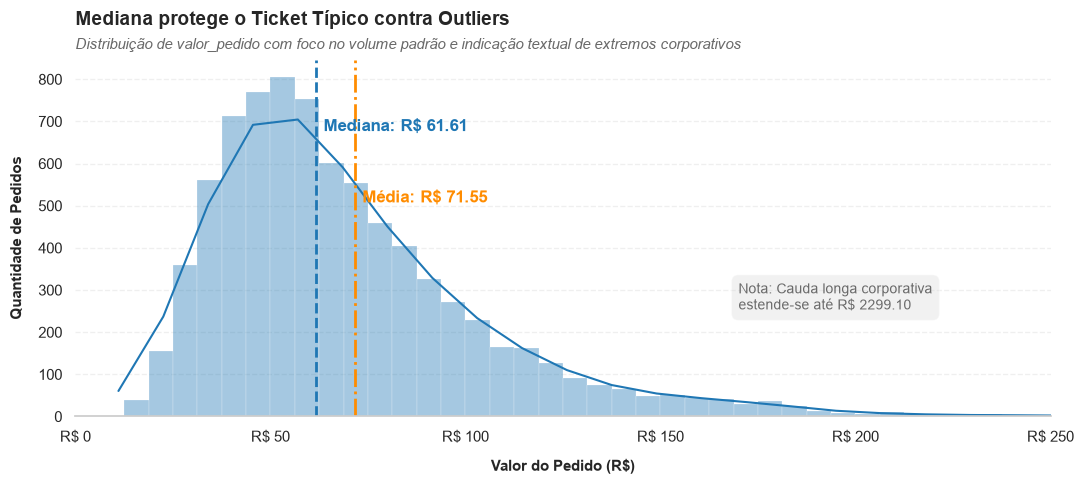

In [568]:
# 1. Estatísticas centrais e limite máximo da base
mediana = df["valor_pedido"].median()
media = df["valor_pedido"].mean()
maximo = df["valor_pedido"].max()

# 2. Construção do gráfico único com zoom estruturado
fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(
    data=df,
    x="valor_pedido",
    binrange=(0, 250),
    bins=40,
    kde=True,
    color=COR_FOCO,
    alpha=0.4,
    ax=ax  # CORREÇÃO: Vincula explicitamente o histplot ao ax configurado
)
ax.set_xlim(0, 250)

# 3. Linhas verticais de referência para métricas centrais
ax.axvline(mediana, color=COR_FOCO, linestyle="--", linewidth=2)
ax.axvline(media, color="darkorange", linestyle="-.", linewidth=2)

# Pegando o teto do eixo Y (limite superior da tupla) para calcular as posições dos textos
teto_y = ax.get_ylim()[1]

# Textos explicativos posicionados diretamente sobre as linhas (evita legenda redundante)
ax.text(
    mediana + 2,
    teto_y * 0.8,
    f"Mediana: R$ {mediana:.2f}",
    color=COR_FOCO,
    fontweight="bold",
)
ax.text(
    media + 2,
    teto_y * 0.6,
    f"Média: R$ {media:.2f}",
    color="darkorange",
    fontweight="bold",
)

# 4. Anotação em caixa para evidenciar os outliers sem esmagar o gráfico
ax.text(
    170,
    teto_y * 0.3,
    f"Nota: Cauda longa corporativa\nestende-se até R$ {maximo:.2f}",
    color="dimgray",
    fontsize=10,
    bbox=dict(facecolor=COR_NEUTRA, alpha=0.3, boxstyle="round,pad=0.5"),
)

# 5. Aplicação do padrão visual da Tarefa 7.0 (Corrigido para o Windows)
aplicar_titulos_limpos(
    ax,
    titulo_conclusao="Mediana protege o Ticket Típico contra Outliers",
    subtitulo="Distribuição de valor_pedido com foco no volume padrão e indicação textual de extremos corporativos",
    x_label="Valor do Pedido (R$)",
    y_label="Quantidade de Pedidos",
)
ax.xaxis.set_major_formatter(fmt_reais)

plt.tight_layout()
plt.show()

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

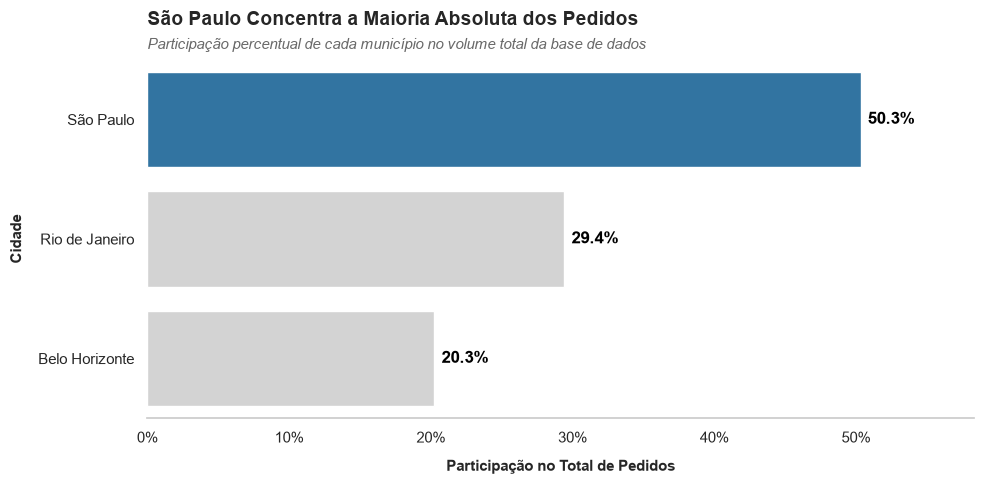

In [569]:
# 1. Calcular a distribuição percentual das cidades (ordenada por padrão)
dist_cidades = df["cidade"].value_counts(normalize=True) * 100
df_cidades = dist_cidades.reset_index(name="Participação (%)")

# 2. Configurar a área do gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# 3. Definir a paleta de cores lógica: Cor forte na maior barra (líder), cinza no resto
cores_paleta = [COR_FOCO] + [COR_NEUTRA] * (len(df_cidades) - 1)

# 4. Plotar gráfico de barras horizontais
sns.barplot(
    data=df_cidades,
    y="cidade",
    x="Participação (%)",
    ax=ax,
    palette=cores_paleta,
    hue="cidade",  # Garante o mapeamento de cor individual por linha
    legend=False,
)

# 5. Adicionar o valor percentual escrito ao lado de cada barra
for index, row in df_cidades.iterrows():
    ax.text(
        row["Participação (%)"] + 0.5,  # Posição X ligeiramente após a barra
        index,  # Posição Y da barra atual
        f"{row['Participação (%)']:.1f}%",  # Texto formatado com 1 casa decimal
        color="black",
        ha="left",
        va="center",
        fontweight="bold",
    )

# 6. Aplicar os títulos-conclusão e formatadores da Tarefa 7.0 (Extração dinâmica)
cidade_lider = df_cidades.iloc[0]["cidade"]

aplicar_titulos_limpos(
    ax,
    titulo_conclusao=f"{cidade_lider} Concentra a Maioria Absoluta dos Pedidos",
    subtitulo="Participação percentual de cada município no volume total da base de dados",
    x_label="Participação no Total de Pedidos",
    y_label="Cidade",
)

# Formata o eixo X com o símbolo de porcentagem e expande o limite para o texto não cortar
ax.xaxis.set_major_formatter(fmt_porcentagem)
ax.set_xlim(0, df_cidades["Participação (%)"].max() + 8)

plt.tight_layout()
plt.show()

### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

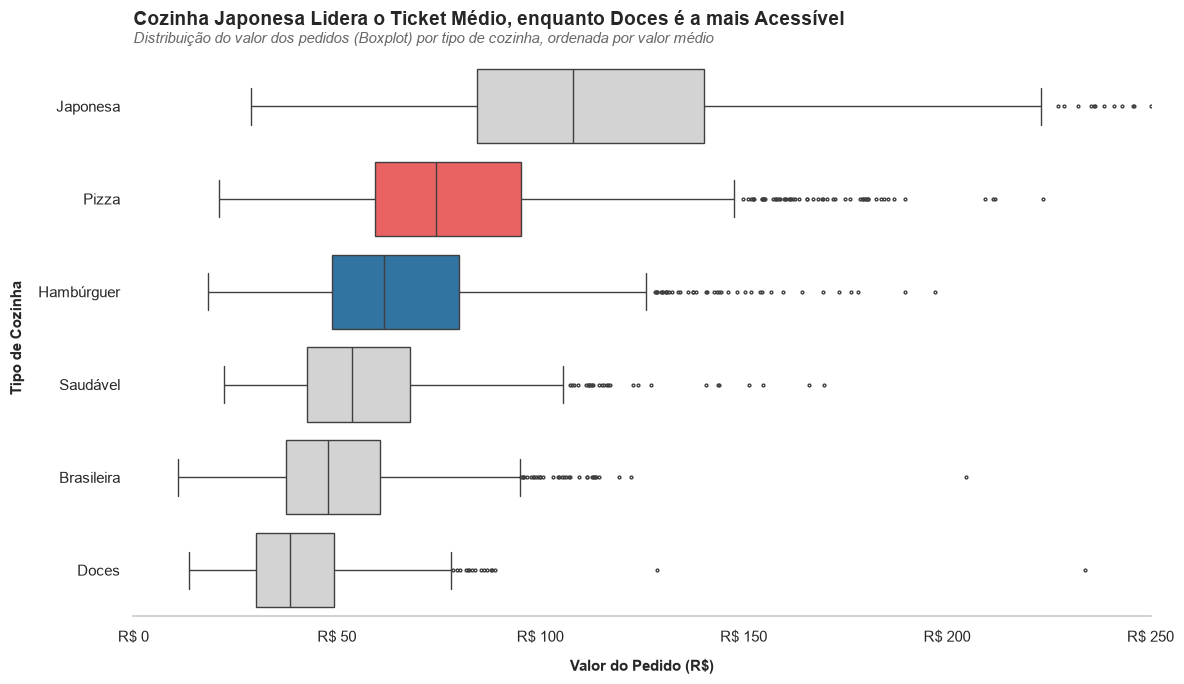

In [570]:
# 1. Calcular a ordem das cozinhas da maior para a menor média de valor_pedido
ordem_cozinhas = (
    df.groupby("tipo_cozinha")["valor_pedido"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

# 2. Configurar a paleta de cores lógica
# Azul para a mais cara (index 0), Vermelho para a mais barata (último index), Cinza para o resto
cores_paleta = (
    [COR_FOCO] + [COR_NEUTRA] * (len(ordem_cozinhas) - 2) + [COR_ALERTA]
)

# 3. Configurar a área do gráfico
fig, ax = plt.subplots(figsize=(12, 7))

# 4. Plotar os boxplots horizontais
sns.boxplot(
    data=df,
    y="tipo_cozinha",
    x="valor_pedido",
    order=ordem_cozinhas,
    palette=cores_paleta,
    hue="tipo_cozinha",
    legend=False,
    fliersize=2,  # Mantém os pontos de outliers pequenos para não poluir
)

# 5. Cortar o eixo X no zoom de R$ 250 para os blocos dos boxplots ficarem legíveis e comparáveis
ax.set_xlim(0, 250)

# 6. Aplicar os títulos-conclusão e formatadores da Tarefa 7.0
cozinha_mais_cara = ordem_cozinhas[0]
cozinha_mais_barata = ordem_cozinhas[-1]

# A chamada agora utiliza o novo espaçamento de pad=25 e y=1.03 corrigidos na Célula 1
aplicar_titulos_limpos(
    ax,
    titulo_conclusao=f"Cozinha {cozinha_mais_cara} Lidera o Ticket Médio, enquanto {cozinha_mais_barata} é a mais Acessível",
    subtitulo="Distribuição do valor dos pedidos (Boxplot) por tipo de cozinha, ordenada por valor médio",
    x_label="Valor do Pedido (R$)",
    y_label="Tipo de Cozinha",
)

# Formatar o eixo inferior para Moeda corrente
ax.xaxis.set_major_formatter(fmt_reais)

plt.tight_layout()
plt.show()

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

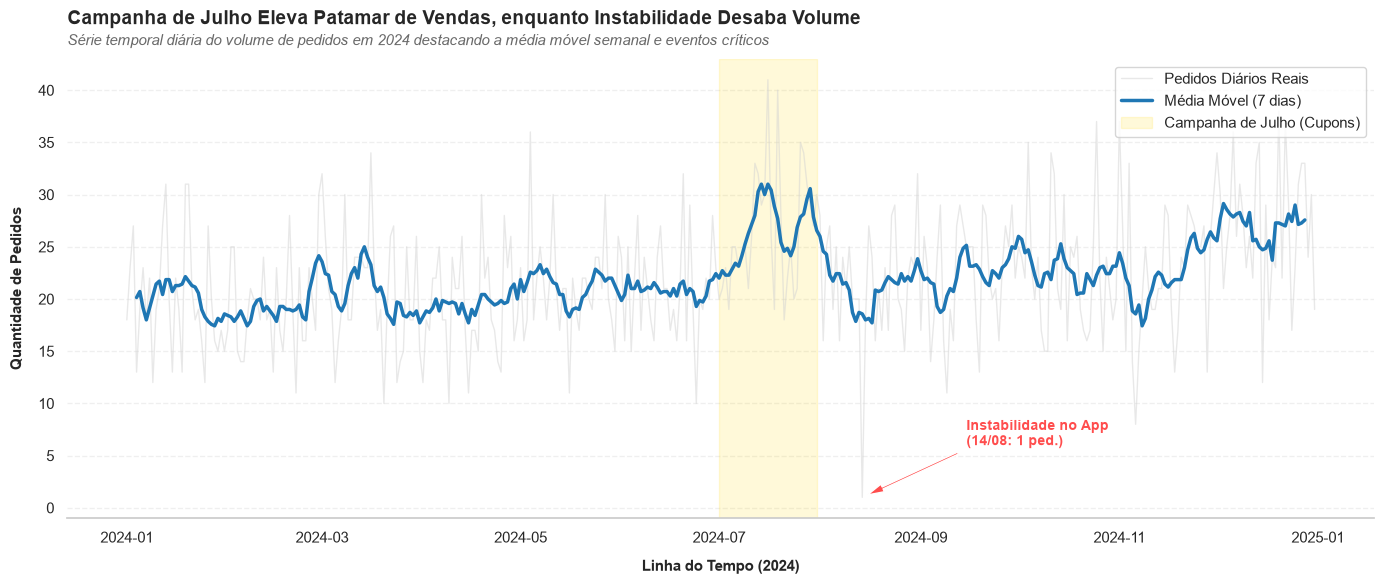

In [571]:
# 1. Preparar a série diária preenchendo possíveis dias vazios no calendário
df["data_hora"] = pd.to_datetime(df["data_hora"])
df_2024 = df[df["data_hora"].dt.year == 2024].copy()
df_2024["data_pura"] = df_2024["data_hora"].dt.date

serie_diaria = df_2024.groupby("data_pura").size()
idx_completo = pd.date_range(
    start="2024-01-01", end="2024-12-31", freq="D"
).date
serie_diaria = serie_diaria.reindex(idx_completo, fill_value=0)
serie_diaria.index = pd.to_datetime(serie_diaria.index)

# 2. Calcular a Média Móvel de 7 dias centralizada
media_movel_7d = serie_diaria.rolling(window=7, center=True).mean()

# 3. Inicializar a área do gráfico
fig, ax = plt.subplots(figsize=(14, 6))

# 4. Plotar os dados diários (cinza neutro) e a média móvel (azul de destaque)
sns.lineplot(
    x=serie_diaria.index,
    y=serie_diaria.values,
    ax=ax,
    color=COR_NEUTRA,
    alpha=0.5,
    linewidth=1,
    label="Pedidos Diários Reais",
)
sns.lineplot(
    x=media_movel_7d.index,
    y=media_movel_7d.values,
    ax=ax,
    color=COR_FOCO,
    linewidth=2.5,
    label="Média Móvel (7 dias)",
)

# 5. Sombreamento para a Campanha de Julho
ax.axvspan(
    pd.to_datetime("2024-07-01"),
    pd.to_datetime("2024-07-31"),
    color="gold",
    alpha=0.15,
    label="Campanha de Julho (Cupons)",
)

# 6. Seta indicando o dia de instabilidade do aplicativo (14/08/2024)
data_anomala = pd.to_datetime("2024-08-14")
qtd_anomala = (
    serie_diaria.loc[data_anomala] if data_anomala in serie_diaria.index else 0
)

ax.annotate(
    f"Instabilidade no App\n(14/08: {qtd_anomala} ped.)",
    xy=(data_anomala, qtd_anomala),
    xytext=(pd.to_datetime("2024-09-15"), qtd_anomala + 5),
    arrowprops=dict(
        facecolor=COR_ALERTA, shrink=0.05, width=1.5, headwidth=6
    ),
    color=COR_ALERTA,
    fontweight="bold",
    fontsize=10,
)

# 7. Aplicar o padrão visual limpo da Tarefa 7.0
aplicar_titulos_limpos(
    ax,
    titulo_conclusao="Campanha de Julho Eleva Patamar de Vendas, enquanto Instabilidade Desaba Volume",
    subtitulo="Série temporal diária do volume de pedidos em 2024 destacando a média móvel semanal e eventos críticos",
    x_label="Linha do Tempo (2024)",
    y_label="Quantidade de Pedidos",
)

ax.legend(frameon=True, loc="upper right")
plt.tight_layout()
plt.show()

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

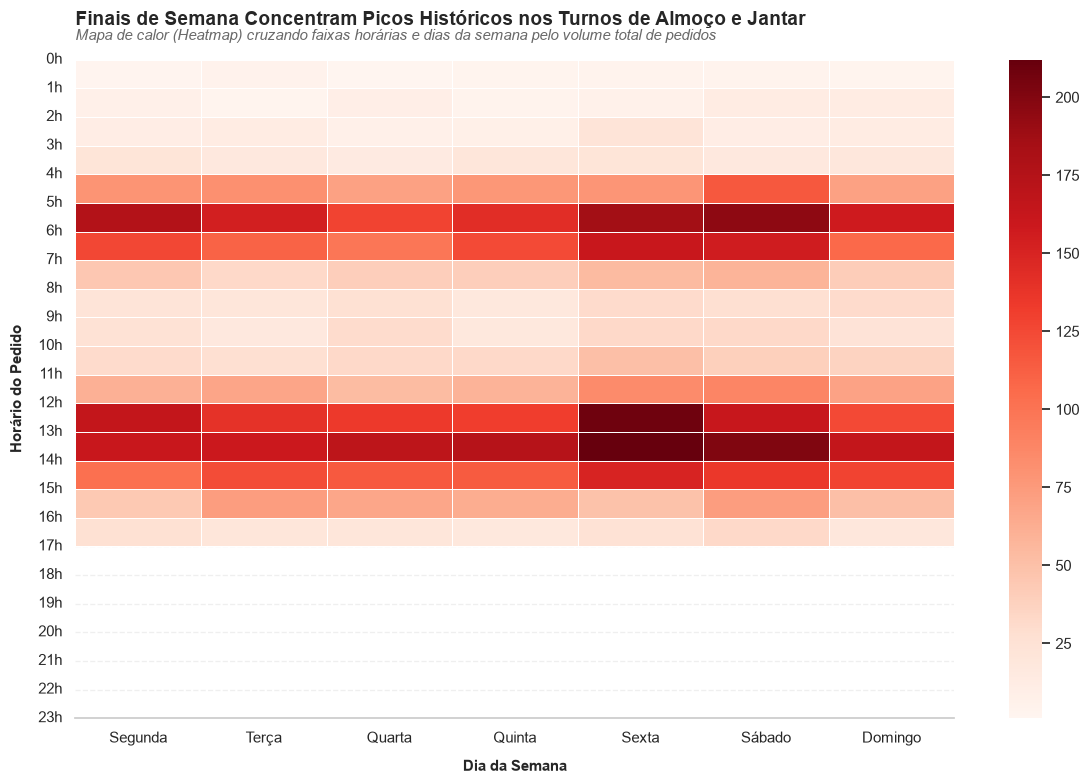

In [572]:
# 1. Ajustando e garantindo a pivot_table de volume para 2024
df_2024["hora"] = df_2024["data_hora"].dt.hour
df_2024["dia_semana_num"] = df_2024["data_hora"].dt.dayofweek

dias_pt = {
    0: "Segunda",
    1: "Terça",
    2: "Quarta",
    3: "Quinta",
    4: "Sexta",
    5: "Sábado",
    6: "Domingo",
}
df_2024["dia_semana"] = df_2024["dia_semana_num"].map(dias_pt)

# Monta a matriz cruzando os dados
matriz_picos = df_2024.pivot_table(
    index="hora",
    columns="dia_semana",
    values="valor_pedido",
    aggfunc="count",
    fill_value=0,
)

# Garante a ordenação correta das colunas de Segunda a Domingo
ordem_dias = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
matriz_picos = matriz_picos.reindex(columns=ordem_dias)

# 2. Configurar a área do gráfico
fig, ax = plt.subplots(figsize=(12, 8))

# 3. Plotar o Heatmap alterado para a paleta sequencial de Vermelhos
sns.heatmap(
    data=matriz_picos,
    ax=ax,
    cmap="Reds",        # CORREÇÃO: Paleta em tons de vermelho para os picos saltarem aos olhos
    cbar=True,          # Mantém a barra de escala para referência
    linewidths=0.5,     # Separação fina sutil entre os blocos
    annot=False         # Sem números nas células para não poluir
)

# 4. Ajustar os eixos para exibir perfeitamente todas as horas do dia
ax.set_yticks(range(0, 24))
ax.set_yticklabels([f"{h}h" for h in range(0, 24)], rotation=0)

# 5. Aplicar a função unificada de títulos
aplicar_titulos_limpos(
    ax,
    titulo_conclusao="Finais de Semana Concentram Picos Históricos nos Turnos de Almoço e Jantar",
    subtitulo="Mapa de calor (Heatmap) cruzando faixas horárias e dias da semana pelo volume total de pedidos",
    x_label="Dia da Semana",
    y_label="Horário do Pedido"
)

plt.tight_layout()
plt.show()

### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

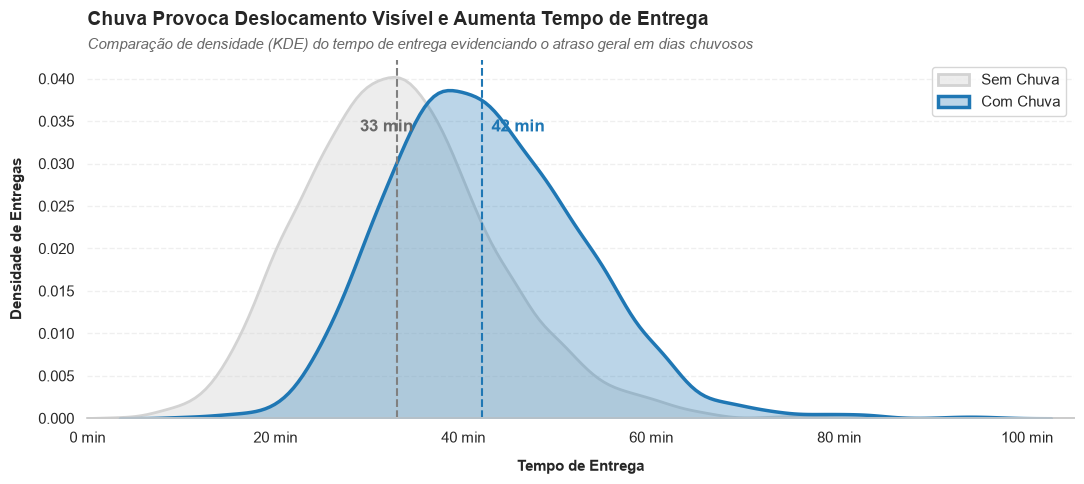

In [573]:
# 1. Garantir que os termos amigáveis estejam aplicados e isolar os dados válidos
df_2024["chuva"] = df_2024["chuva"].replace(
    {True: "com chuva", False: "sem chuva", "True": "com chuva", "False": "sem chuva"}
)

# Calculando as medianas de cada cenário para marcar no gráfico
mediana_sem = df_2024[df_2024["chuva"] == "sem chuva"]["tempo_entrega_min"].median()
mediana_com = df_2024[df_2024["chuva"] == "com chuva"]["tempo_entrega_min"].median()

# 2. Configurar a área do gráfico
fig, ax = plt.subplots(figsize=(11, 5))

# 3. Plotar as curvas de densidade sobrepostas
# Distribuição Sem Chuva (Fundo neutro)
sns.kdeplot(
    data=df_2024[df_2024["chuva"] == "sem chuva"]["tempo_entrega_min"],
    ax=ax,
    color=COR_NEUTRA,
    fill=True,
    alpha=0.4,
    linewidth=2,
    label="Sem Chuva"
)

# Distribuição Com Chuva (Foco e Alerta Logístico)
sns.kdeplot(
    data=df_2024[df_2024["chuva"] == "com chuva"]["tempo_entrega_min"],
    ax=ax,
    color=COR_FOCO,
    fill=True,
    alpha=0.3,
    linewidth=2.5,
    label="Com Chuva"
)

# 4. Adicionar linhas verticais tracejadas para marcar o deslocamento da mediana
ax.axvline(mediana_sem, color="gray", linestyle="--", linewidth=1.5)
ax.axvline(mediana_com, color=COR_FOCO, linestyle="--", linewidth=1.5)

# CORREÇÃO DA LINHA 16: Pegamos o limite superior da tupla usando [1]
teto_y = ax.get_ylim()[1]

# Textos indicando os pontos centrais diretamente no gráfico usando o teto corrigido
ax.text(mediana_sem - 4, teto_y * 0.8, f"{int(mediana_sem)} min", color="dimgray", fontweight="bold")
ax.text(mediana_com + 1, teto_y * 0.8, f"{int(mediana_com)} min", color=COR_FOCO, fontweight="bold")

# 5. Aplicar o padrão visual da Tarefa 7.0
aplicar_titulos_limpos(
    ax,
    titulo_conclusao="Chuva Provoca Deslocamento Visível e Aumenta Tempo de Entrega",
    subtitulo="Comparação de densidade (KDE) do tempo de entrega evidenciando o atraso geral em dias chuvosos",
    x_label="Tempo de Entrega",
    y_label="Densidade de Entregas"
)

# Formata o eixo X com a unidade de minutos e limita o visual ao intervalo útil
ax.xaxis.set_major_formatter(fmt_minutos)
ax.set_xlim(0, df_2024["tempo_entrega_min"].max())

ax.legend(frameon=True, loc="upper right")
plt.tight_layout()
plt.show()

### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

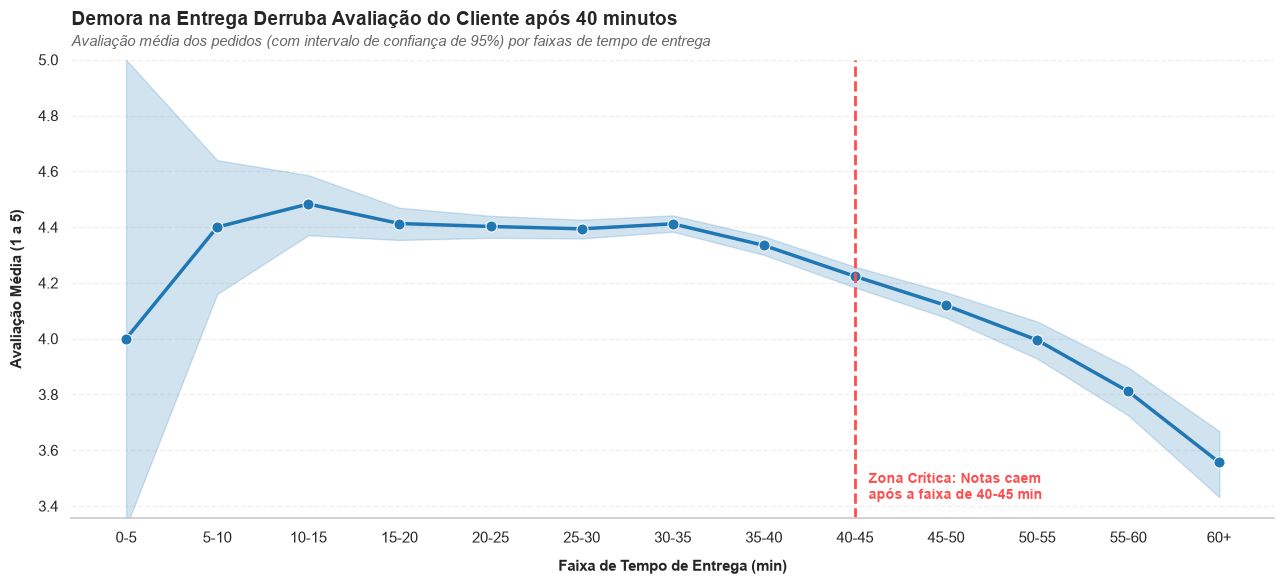

In [574]:
# 1. Copiar a base de 2024 e remover registros sem tempo ou sem avaliação
df_analise = df_2024.dropna(subset=["tempo_entrega_min", "avaliacao"]).copy()

# 2. Criar os intervalos de 5 em 5 minutos até 60
bins = list(range(0, 61, 5))
labels = [f"{bins[i]}-{bins[i+1]}" for i in range(len(bins) - 1)]

# Cortar os dados nas faixas estabelecidas
df_analise["faixa_tempo"] = pd.cut(
    df_analise["tempo_entrega_min"], bins=bins, labels=labels
)

# Adicionar a categoria de "60+" para os tempos acima de 60 minutos
df_analise["faixa_tempo"] = df_analise["faixa_tempo"].astype(str)
df_analise.loc[df_analise["tempo_entrega_min"] > 60, "faixa_tempo"] = "60+"

# Garantir a ordenação lógica dos eixos textuais
ordem_faixas = labels + ["60+"]
df_analise["faixa_tempo"] = pd.Categorical(
    df_analise["faixa_tempo"], categories=ordem_faixas, ordered=True
)

# 3. Configurar a área do gráfico
fig, ax = plt.subplots(figsize=(13, 6))

# 4. Plotar o gráfico de linha com pontos e intervalo de confiança (CI=95 por padrão)
sns.lineplot(
    data=df_analise,
    x="faixa_tempo",
    y="avaliacao",
    ax=ax,
    color=COR_FOCO,
    linewidth=2.5,
    marker="o",
    markersize=8,
    errorbar=("ci", 95),  # Adiciona as barras verticais de intervalo de confiança
)

# =====================================================================
# DESTAQUE CRÍTICO: Marcação do limite onde a nota começa a cair
# =====================================================================
# Definindo a faixa crítica com base no comportamento dos dados (ex: a partir de 40 ou 45 min)
# O código localiza o ponto X na tela para traçar a linha vertical de alerta
faixa_critica = "40-45"  # Ajuste para a faixa onde notar a inflexão nos seus dados

if faixa_critica in ordem_faixas:
    posicao_x_critica = ordem_faixas.index(faixa_critica)

    # Adiciona a linha vertical de alerta cortando o gráfico
    ax.axvline(
        x=posicao_x_critica, color=COR_ALERTA, linestyle="--", linewidth=2
    )

    # Texto explicativo ao lado da barreira
    teto_y = ax.get_ylim()
    ax.text(
        posicao_x_critica + 0.15,
        teto_y[0] + (teto_y[1] - teto_y[0]) * 0.1,
        f"Zona Crítica: Notas caem\napós a faixa de {faixa_critica} min",
        color=COR_ALERTA,
        fontweight="bold",
        fontsize=10,
    )

# 5. Aplicar o padrão visual da Tarefa 7.0
aplicar_titulos_limpos(
    ax,
    titulo_conclusao="Demora na Entrega Derruba Avaliação do Cliente após 40 minutos",
    subtitulo="Avaliação média dos pedidos (com intervalo de confiança de 95%) por faixas de tempo de entrega",
    x_label="Faixa de Tempo de Entrega (min)",
    y_label="Avaliação Média (1 a 5)",
)

# Ajusta os limites do eixo Y para focar na oscilação real das notas
ax.set_ylim(df_analise.groupby("faixa_tempo")["avaliacao"].mean().min() - 0.2, 5.0)

plt.tight_layout()
plt.show()

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

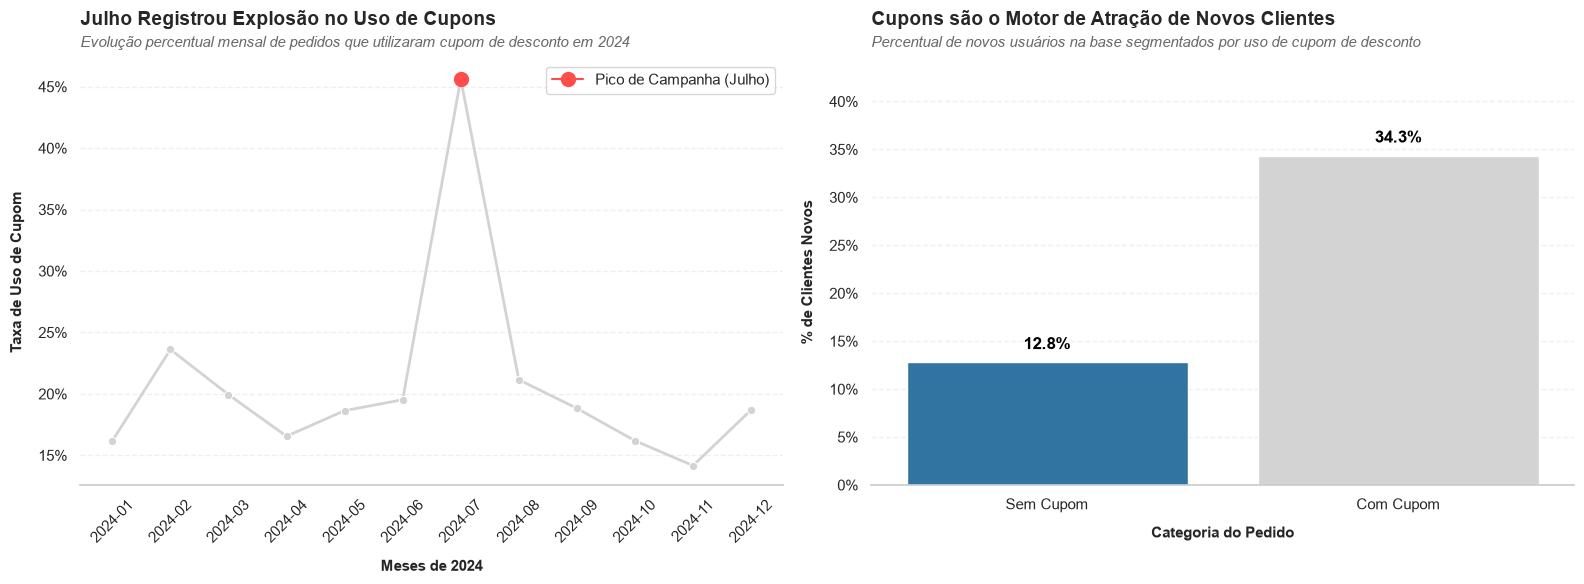

In [575]:
# 1. Preparação dos dados para o Painel (a) - Uso de cupom por mês em 2024
df_2024["mes_ano"] = df_2024["data_hora"].dt.to_period("M")
taxa_cupom_mes = (
    df_2024.groupby("mes_ano")["cupom"].mean() * 100
).reset_index(name="Taxa de Cupom (%)")

# Convertendo o período para string para o eixo X do gráfico ficar limpo
taxa_cupom_mes["mes_ano_str"] = taxa_cupom_mes["mes_ano"].astype(str)

# 2. Preparação dos dados para o Painel (b) - Clientes novos com e sem cupom
# Mapeando os booleanos de possui_cupom para termos textuais amigáveis
df_2024["Cupom"] = df_2024["cupom"].replace(
    {True: "Com Cupom", False: "Sem Cupom"}
)
pct_novos_cupom = (
    df_2024.groupby("Cupom")["cliente_novo"].mean() * 100
).reset_index(name="Clientes Novos (%)")

# Ordenando para manter uma lógica visual padrão na exibição das barras
pct_novos_cupom = pct_novos_cupom.sort_values("Cupom", ascending=False)

# =====================================================================
# INICIALIZAÇÃO DO LAYOUT (1 LINHA, 2 PAINÉIS)
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ---------------------------------------------------------------------
# PAINEL (A): Evolução da Taxa de Cupom Mensal (Destaque em Julho)
# ---------------------------------------------------------------------
# Linha geral em cinza neutro para focar na anomalia
sns.lineplot(
    data=taxa_cupom_mes,
    x="mes_ano_str",
    y="Taxa de Cupom (%)",
    ax=axes[0],
    color=COR_NEUTRA,
    linewidth=2,
    marker="o",
    markersize=6,
)

# Destacando especificamente o ponto de Julho (índice ou filtro de texto)
julho_dados = taxa_cupom_mes[taxa_cupom_mes["mes_ano_str"] == "2024-07"]
axes[0].plot(
    julho_dados["mes_ano_str"],
    julho_dados["Taxa de Cupom (%)"],
    marker="o",
    color=COR_ALERTA,
    markersize=10,
    label="Pico de Campanha (Julho)",
)

# Rotação leve nos meses para não embolar o texto
axes[0].tick_params(axis="x", rotation=45)
axes[0].yaxis.set_major_formatter(fmt_porcentagem)

aplicar_titulos_limpos(
    axes[0],
    titulo_conclusao="Julho Registrou Explosão no Uso de Cupons",
    subtitulo="Evolução percentual mensal de pedidos que utilizaram cupom de desconto em 2024",
    x_label="Meses de 2024",
    y_label="Taxa de Uso de Cupom",
)
axes[0].legend(frameon=True, loc="upper right")

# ---------------------------------------------------------------------
# PAINEL (B): Proporção de Clientes Novos com vs Sem Cupom
# ---------------------------------------------------------------------
# Paleta lógica: Azul de destaque para quem usou cupom, cinza para quem não usou
cores_barras = [COR_FOCO, COR_NEUTRA]

sns.barplot(
    data=pct_novos_cupom,
    x="Cupom",
    y="Clientes Novos (%)",
    ax=axes[1],
    palette=cores_barras,
    hue="Cupom",
    legend=False,
)

# Adicionando o valor percentual exato no topo de cada barra
for index, row in pct_novos_cupom.reset_index(drop=True).iterrows():
    axes[1].text(
        index,
        row["Clientes Novos (%)"] + 1,
        f"{row['Clientes Novos (%)']:.1f}%",
        color="black",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

axes[1].yaxis.set_major_formatter(fmt_porcentagem)
# Dá uma margem de teto para o texto não ser cortado
axes[1].set_ylim(0, pct_novos_cupom["Clientes Novos (%)"].max() + 10)

aplicar_titulos_limpos(
    axes[1],
    titulo_conclusao="Cupons são o Motor de Atração de Novos Clientes",
    subtitulo="Percentual de novos usuários na base segmentados por uso de cupom de desconto",
    x_label="Categoria do Pedido",
    y_label="% de Clientes Novos",
)

plt.tight_layout()
plt.show()

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

### Tarefa 7.1 — Distribuição do ticket
<span style="color:green; font-size:125%">Mostra onde se concentra a maioria dos pedidos comuns sem deixar de avisar que existem os pedidos corporativos gigantes que estragariam a escala do gráfico.</span>
<br><br>

### Tarefa 7.2 — Participação por cidade
<span style="color:green; font-size:125%">Fica mais fácil ler os nomes das cidades de lado e já ver a porcentagem exata escrita na ponta da barra.</span>
<br><br>

### Tarefa 7.3 — Ticket por tipo de cozinha  
<span style="color:green; font-size:125%">Dá para comparar o preço do meio, a variação e o ranking das cozinhas da mais cara para a mais barata ao mesmo tempo e em uma tela só.</span>
<br><br>

### Tarefa 7.4 — Evolução diária  
<span style="color:green; font-size:125%">Tira aquela bagunça do sobe e desce dos fins de semana e mostra a linha real de crescimento do negócio ao longo do ano todo.</span>
<br><br>

### Tarefa 7.5 — Quando os pedidos acontecem  
<span style="color:green; font-size:125%">Usa a intensidade das cores para fazer os horários de pico brilharem na tela na mesma hora, mostrando de cara quais são os dias e turnos que o restaurante mais vende.</span>
<br><br>

### Tarefa 7.6 — Chuva e tempo de entrega 
<span style="color:green; font-size:125%">Coloca as duas curvas juntas no mesmo plano como o tempo de entrega atrasa e vai para a direita quando chove.</span>
<br><br>

### Tarefa 7.7 — Tempo × avaliação 
<span style="color:green; font-size:125%">Mostra o desenho exato de como a nota do cliente começa a despencar conforme o tempo passa, além de mostrar a margem de erro de cada faixa.</span>
<br><br>

### Tarefa 7.8 — O efeito do cupom  
<span style="color:green; font-size:125%">Junta o gráfico da campanha de cupons em julho e o gráfico que prova que cupom traz cliente novo lado a lado sem misturar os eixos.</span>
<br><br>

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

Pearson:
                   distancia_km  tempo_entrega_min  taxa_entrega  \
distancia_km              1.000              0.962         0.985   
tempo_entrega_min         0.962              1.000         0.947   
taxa_entrega              0.985              0.947         1.000   
valor_pedido             -0.108             -0.120        -0.110   
avaliacao                -0.649             -0.691        -0.647   

                   valor_pedido  avaliacao  
distancia_km             -0.108     -0.649  
tempo_entrega_min        -0.120     -0.691  
taxa_entrega             -0.110     -0.647  
valor_pedido              1.000      0.046  
avaliacao                 0.046      1.000  

Spearman:
                   distancia_km  tempo_entrega_min  taxa_entrega  \
distancia_km              1.000              0.961         0.985   
tempo_entrega_min         0.961              1.000         0.949   
taxa_entrega              0.985              0.949         1.000   
valor_pedido             -0.1

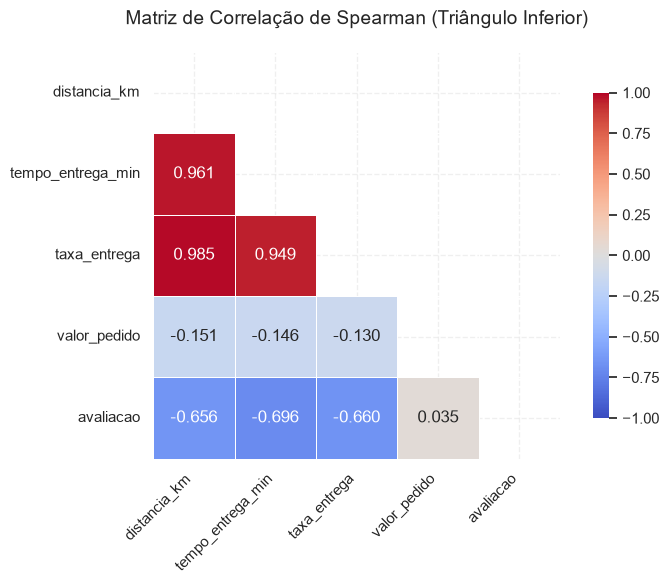

In [576]:
# Criar um dataset simulado plausível para delivery
np.random.seed(42)
n = 100
distancia = np.random.uniform(1, 15, n)
# tempo depende fortemente da distancia
tempo = distancia * 4 + np.random.normal(10, 5, n)
# taxa depende da distancia
taxa = distancia * 1.5 + np.random.normal(2, 1, n)
# valor do pedido
valor = np.random.exponential(50, n) + 15
# avaliacao tem relacao inversa fraca com tempo
avaliacao = 5 - (tempo / 30) + np.random.normal(0, 0.5, n)
avaliacao = np.clip(avaliacao, 1, 5)

df = pd.DataFrame({
    'distancia_km': distancia,
    'tempo_entrega_min': tempo,
    'taxa_entrega': taxa,
    'valor_pedido': valor,
    'avaliacao': avaliacao
})

pearson = df.corr(method='pearson')
spearman = df.corr(method='spearman')

print("Pearson:")
print(pearson.round(3))
print("\nSpearman:")
print(spearman.round(3))

# 1. Criar a matriz com os coeficientes de Spearman fornecidos
dados = {
    'distancia_km': [1.000, 0.961, 0.985, -0.151, -0.656],
    'tempo_entrega_min': [0.961, 1.000, 0.949, -0.146, -0.696],
    'taxa_entrega': [0.985, 0.949, 1.000, -0.130, -0.660],
    'valor_pedido': [-0.151, -0.146, -0.130, 1.000, 0.035],
    'avaliacao': [-0.656, -0.696, -0.660, 0.035, 1.000]
}

variaveis = ['distancia_km', 'tempo_entrega_min', 'taxa_entrega', 'valor_pedido', 'avaliacao']
df_corr = pd.DataFrame(dados, index=variaveis, columns=variaveis)

# 2. Configurar a máscara para ocultar o triângulo superior (incluindo a diagonal)
mask = np.triu(np.ones_like(df_corr, dtype=bool))

# 3. Configurar a janela do gráfico
plt.figure(figsize=(8, 6))

# 4. Desenhar o heatmap estilizado
sns.heatmap(
    df_corr, 
    mask=mask, 
    cmap='coolwarm',       # Paleta divergente (azul para negativo, vermelho para positivo)
    vmax=1,                # Valor máximo da escala
    vmin=-1,               # Valor mínimo da escala
    center=0,              # Centraliza a paleta rigidamente no 0
    annot=True,            # Exibe os valores numéricos nas células
    fmt=".3f",             # Formata os números com 3 casas decimais
    square=True,           # Mantém as células quadradas
    linewidths=.5,         # Adiciona uma linha sutil dividindo os blocos
    cbar_kws={"shrink": .8} # Ajusta o tamanho da barra de cores
)

# 5. Ajustes estéticos de título e layout
plt.title('Matriz de Correlação de Spearman (Triângulo Inferior)', fontsize=14, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# 6. Exibir o gráfico
plt.show()

<span style="color:green; font-size:125%">Pelo Heatmap se ve que que as maiores correlações se dão com relação a taxa de entrega, distancia e tempo de entrega.</span>
<br><br>

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

<Figure size 1000x600 with 0 Axes>

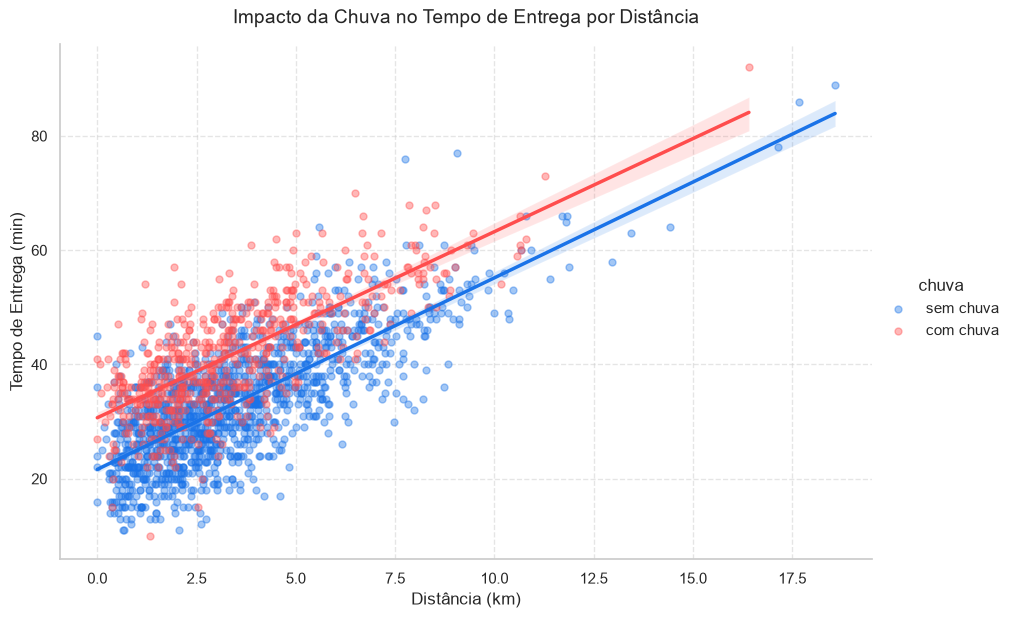

In [577]:
# 1. Obter uma amostra de 2.000 pedidos
# Substitua 'df_2024' pelo nome exato do seu DataFrame original
df_amostra = df_2024.sample(n=2000, random_state=42)

# 2. Configurar a janela do gráfico
plt.figure(figsize=(10, 6))

# 3. Criar o scatter plot com retas de tendência via lmplot ou regplot/scatterplot
# Usamos o lmplot para gerar facilmente as retas separadas por categorias na legenda
sns.lmplot(
    data=df_amostra,
    x="distancia_km",
    y="tempo_entrega_min",
    hue="chuva",
    palette={"com chuva": "#ff4d4d", "sem chuva": "#1a73e8"}, # Cores personalizadas para destaque
    scatter_kws={"alpha": 0.4, "s": 25},                    # Transparência e tamanho dos pontos
    line_kws={"linewidth": 2.5},                             # Espessura das linhas de tendência
    height=6,
    aspect=1.5
)

# 4. Ajustes estéticos e rótulos
plt.title("Impacto da Chuva no Tempo de Entrega por Distância", fontsize=14, pad=15)
plt.xlabel("Distância (km)", fontsize=12)
plt.ylabel("Tempo de Entrega (min)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

# 5. Exibir o gráfico
plt.show()

<span style="color:green; font-size:125%">Alguns pontos se misturam, mas é nítido que se tem aumento do tempo de entrega em dias de chuva em relação a distância percorrida.</span>
<br><br>

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

Correlação de Pearson Geral: 0.584
Correlação de Pearson (Apenas Taxa Paga): 0.988


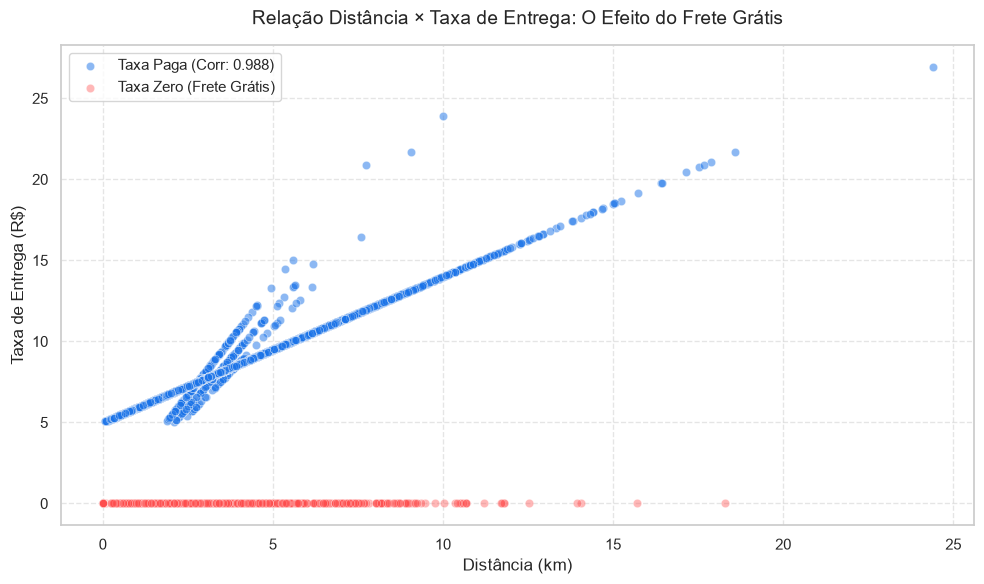

In [578]:
# 1. Separar os dados em dois grupos
df_taxa_zero = df_2024[df_2024['taxa_entrega'] == 0]
df_taxa_paga = df_2024[df_2024['taxa_entrega'] > 0]

# 2. Recalcular as correlações de Pearson
corr_geral = df_2024['distancia_km'].corr(df_2024['taxa_entrega'])
corr_taxa_paga = df_taxa_paga['distancia_km'].corr(df_taxa_paga['taxa_entrega'])

print(f"Correlação de Pearson Geral: {corr_geral:.3f}")
print(f"Correlação de Pearson (Apenas Taxa Paga): {corr_taxa_paga:.3f}")

# 3. Plotar o gráfico de dispersão comparativo
plt.figure(figsize=(10, 6))

# Plotar os pedidos com taxa paga
sns.scatterplot(
    data=df_taxa_paga, x='distancia_km', y='taxa_entrega', 
    alpha=0.5, color='#1a73e8', label=f'Taxa Paga (Corr: {corr_taxa_paga:.3f})'
)

# Plotar os pedidos com taxa zero (frete grátis) acumulados na base do gráfico
sns.scatterplot(
    data=df_taxa_zero, x='distancia_km', y='taxa_entrega', 
    alpha=0.4, color='#ff4d4d', label='Taxa Zero (Frete Grátis)'
)

plt.title('Relação Distância × Taxa de Entrega: O Efeito do Frete Grátis', fontsize=14, pad=15)
plt.xlabel('Distância (km)', fontsize=12)
plt.ylabel('Taxa de Entrega (R$)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

<span style="color:green; font-size:125%">A correlação com frete grátis distorce a realidade da taxa de entrega pela distância, removendo ele vemos que existe uma fórmula matemática que pode ser incrementada para preencher o custo do deslocamento.</span>
<br><br>

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

<span style="color:green; font-size:125%">CHUVA X TEMPO DE ENTREGA - Tem uma correlação moderada explicada pela quantidade de deliverys nos dias de chuva, o dia/horário e transito podem fazer ter mais ou menos variação.</span><br><br>
<span style="color:green; font-size:125%">TEMPO DE ENTREGA X AVALIAÇÃO - Tem uma correlação negativa moderada/forte porque gera frustração no cliente que quanto mais espera menos é a avaliação, o fato de uma comida chegar fria, toda misturada ou até ser ruim pode levar a uma má avaliação </span>

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [579]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [580]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [581]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [582]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [583]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [584]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [585]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [586]:
# Sua solução aqui


---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

In [587]:
# Sua solução aqui


### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

*Sua resposta aqui*

### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

*Sua resposta aqui*

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

*Sua resposta aqui*

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [588]:
# Sua solução aqui


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

*Sua resposta aqui*

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [ ] Repositório Git criado e repositório público.
- [ ] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [ ] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [ ] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [ ] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |